# Human Action Detection

## Step 1: Importing Libraries

In [3]:
import os
print(os.getcwd())


C:\Users\mahar\Desktop\ML\Machine.ipynb


In [4]:
print(os.listdir())


['.ipynb_checkpoints', 'diabetes.csv', 'Diabetes_prediction.ipynb', 'Human Action Detection.ipynb', 'Machine', 'Machine.ipynb', 'mhealth_raw_data.csv', 'untitled.txt']


In [5]:
import pandas as pd
df = pd.read_csv("mhealth_raw_data.csv")
print(df.head())


      alx     aly      alz       glx      gly      glz     arx     ary  \
0  2.1849 -9.6967  0.63077  0.103900 -0.84053 -0.68762 -8.6499 -4.5781   
1  2.3876 -9.5080  0.68389  0.085343 -0.83865 -0.68369 -8.6275 -4.3198   
2  2.4086 -9.5674  0.68113  0.085343 -0.83865 -0.68369 -8.5055 -4.2772   
3  2.1814 -9.4301  0.55031  0.085343 -0.83865 -0.68369 -8.6279 -4.3163   
4  2.4173 -9.3889  0.71098  0.085343 -0.83865 -0.68369 -8.7008 -4.1459   

        arz      grx     gry       grz  Activity   subject  
0  0.187760 -0.44902 -1.0103  0.034483         0  subject1  
1  0.023595 -0.44902 -1.0103  0.034483         0  subject1  
2  0.275720 -0.44902 -1.0103  0.034483         0  subject1  
3  0.367520 -0.45686 -1.0082  0.025862         0  subject1  
4  0.407290 -0.45686 -1.0082  0.025862         0  subject1  


## STEP 1:

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
from sklearn.utils import resample
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import statsmodels.api as sm

In [9]:
from sklearn.metrics import classification_report, r2_score

In [10]:
from sklearn.metrics import classification_report, r2_score, accuracy_score, recall_score, \
precision_score, f1_score, confusion_matrix, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

## Step 2: Data importing and analysing


In [11]:
df=pd.read_csv("mhealth_raw_data.csv")
df

,alx,aly,alz,glx,gly,glz,arx,ary,arz,grx,gry,grz,Activity,subject
0,2.1849,-9.6967,0.63077,0.103900,-0.84053,-0.68762,-8.6499,-4.5781,0.187760,-0.449020,-1.01030,0.034483,0,subject1
1,2.3876,-9.5080,0.68389,0.085343,-0.83865,-0.68369,-8.6275,-4.3198,0.023595,-0.449020,-1.01030,0.034483,0,subject1
2,2.4086,-9.5674,0.68113,0.085343,-0.83865,-0.68369,-8.5055,-4.2772,0.275720,-0.449020,-1.01030,0.034483,0,subject1
3,2.1814,-9.4301,0.55031,0.085343,-0.83865,-0.68369,-8.6279,-4.3163,0.367520,-0.456860,-1.00820,0.025862,0,subject1
4,2.4173,-9.3889,0.71098,0.085343,-0.83865,-0.68369,-8.7008,-4.1459,0.407290,-0.456860,-1.00820,0.025862,0,subject1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1215740,1.7849,-9.8287,0.29725,-0.341370,-0.90056,-0.61493,-3.7198,-8.9071,0.294230,0.041176,-0.99384,-0.480600,0,subject10
1215741,1.8687,-9.8766,0.46236,-0.341370,-0.90056,-0.61493,-3.7160,-8.7455,0.448140,0.041176,-0.99384,-0.480600,0,subject10
1215742,1.6928,-9.9290,0.16631,-0.341370,-0.90056,-0.61493,-3.8824,-9.1155,0.450480,0.041176,-0.99384,-0.480600,0,subject10
1215743,1.5279,-9.6306,0.30458,-0.341370,-0.90056,-0.61493,-3.5564,-9.1441,0.594880,0.041176,-0.99384,-0.480600,0,subject10


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1215745 entries, 0 to 1215744
Data columns (total 14 columns):
 #   Column    Non-Null Count    Dtype  
---  ------    --------------    -----  
 0   alx       1215745 non-null  float64
 1   aly       1215745 non-null  float64
 2   alz       1215745 non-null  float64
 3   glx       1215745 non-null  float64
 4   gly       1215745 non-null  float64
 5   glz       1215745 non-null  float64
 6   arx       1215745 non-null  float64
 7   ary       1215745 non-null  float64
 8   arz       1215745 non-null  float64
 9   grx       1215745 non-null  float64
 10  gry       1215745 non-null  float64
 11  grz       1215745 non-null  float64
 12  Activity  1215745 non-null  int64  
 13  subject   1215745 non-null  object 
dtypes: float64(12), int64(1), object(1)
memory usage: 129.9+ MB


In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
alx,1215745.0,1.494200,3.826485,-22.1460,0.14131,1.308900,2.575800,20.0540
aly,1215745.0,-9.692878,4.171303,-19.6190,-10.20100,-9.670300,-9.042200,21.1610
alz,1215745.0,-0.954806,5.461803,-19.3730,-2.64940,-0.016456,1.301300,25.0150
glx,1215745.0,-0.001599,0.491217,-2.1466,-0.43599,-0.014842,0.448980,60.4840
gly,1215745.0,-0.616632,0.354641,-7.7899,-0.81801,-0.707320,-0.540340,2.0113
glz,1215745.0,-0.158781,0.546798,-2.6267,-0.59332,-0.190570,0.322200,2.7701
arx,1215745.0,-3.713413,4.763586,-22.3610,-6.07600,-2.977600,-1.193700,19.8640
ary,1215745.0,-5.805526,5.757639,-18.9720,-9.40420,-7.461500,-2.533900,22.1910
arz,1215745.0,2.393880,3.876503,-18.2390,0.12965,1.928100,4.914700,25.7410
grx,1215745.0,-0.276106,0.527689,-8.3392,-0.70588,-0.354900,0.096078,3.3196


In [14]:
df.isnull().sum()

alx         0
aly         0
alz         0
glx         0
gly         0
glz         0
arx         0
ary         0
arz         0
grx         0
gry         0
grz         0
Activity    0
subject     0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='Activity'>

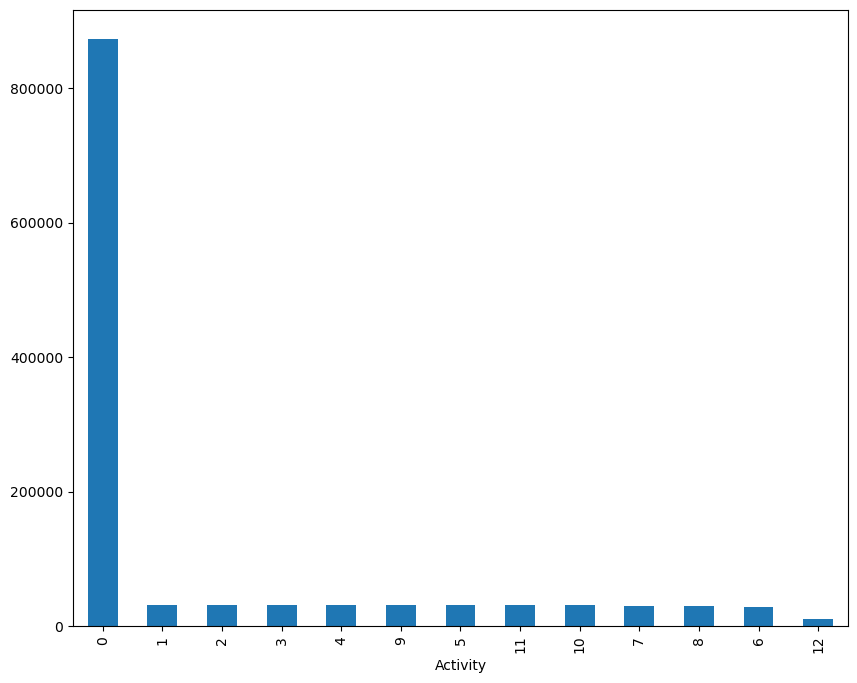

In [16]:
plt.figure(figsize=(10,8))
df['Activity'].value_counts().plot.bar()

In [17]:
data_activity_0 =df[df["Activity"] == 0]
data_activity_else = df[df["Activity"] != 0]

In [18]:
data_activity_0 = data_activity_0.sample(n=40000)
df = pd.concat([data_activity_0, data_activity_else])

<Axes: xlabel='Activity'>

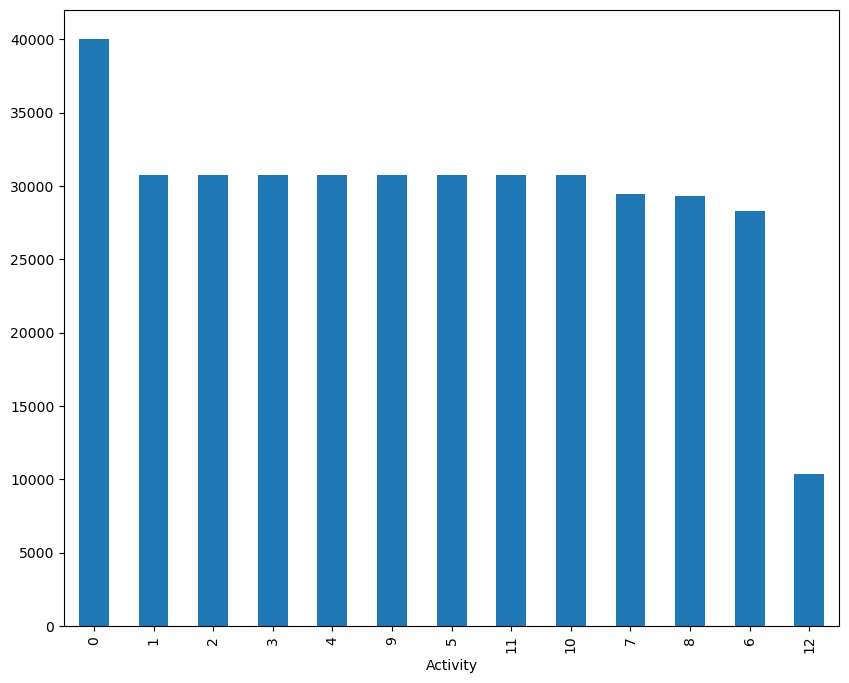

In [19]:
plt.figure(figsize=(10,8))
df['Activity'].value_counts().plot.bar()

In [20]:
len(df)

383195

## Step 3: EDA

In [21]:
activity_label = {
    0: "None",
    1: "Standing still (1 min)",
    2: "Sitting and relaxing (1 min)",
    3: "Lying down (1 min)",
    4:"Walking (1 min)",
    5: "Climbing stairs (1 min)",
    6: "Waist bends forward (20x)",
    7: "Frontal elevation of arms (20x)",
    8: "Knees bending (crouching) (20x)",
    9: "Cycling (1 min)",
    10: "Jogging (1 min)",
    11: "Running (1 min)",
    12: "Jump front & back (20x)"
}

 =================Standing still (1 min) - a===================


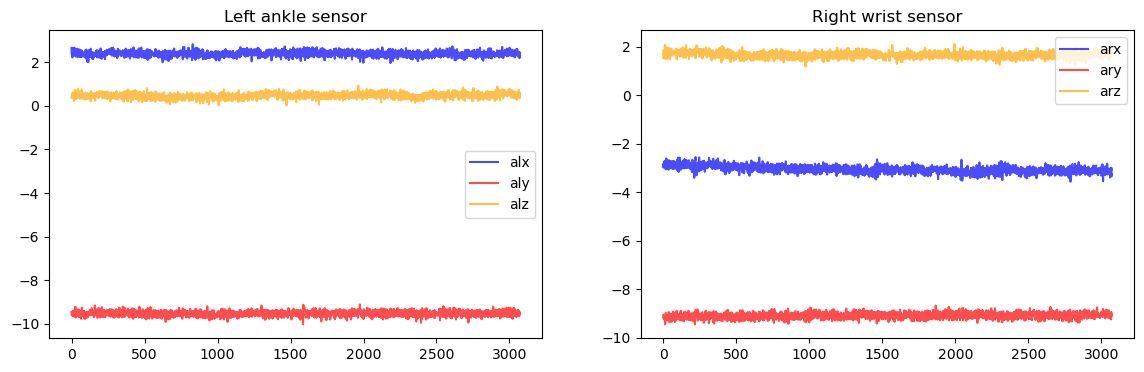

 =================Standing still (1 min) - g===================


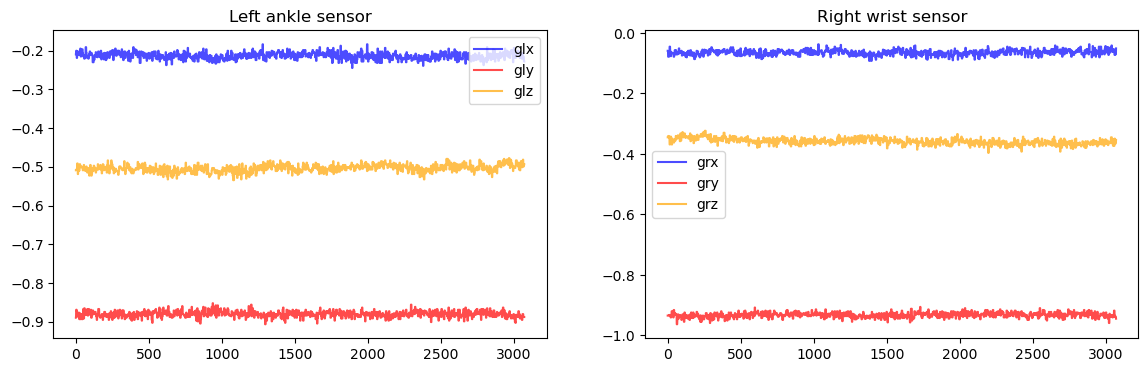

 =================Sitting and relaxing (1 min) - a===================


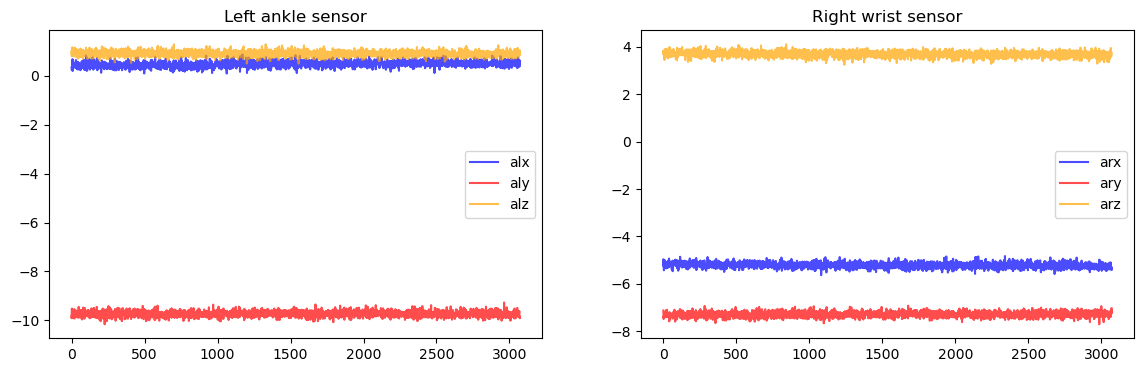

 =================Sitting and relaxing (1 min) - g===================


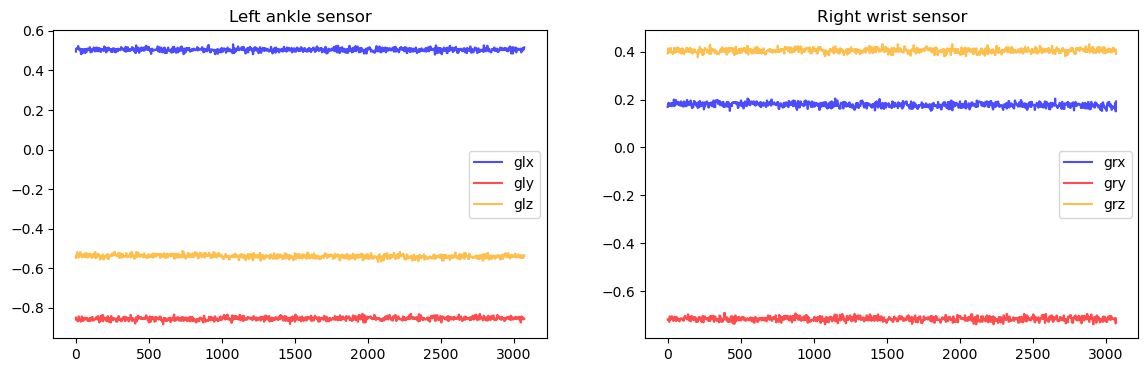

 =================Lying down (1 min) - a===================


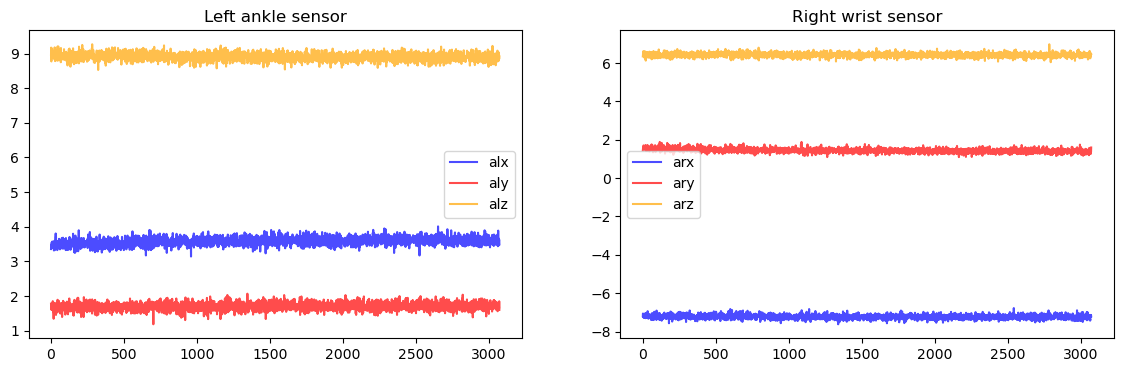

 =================Lying down (1 min) - g===================


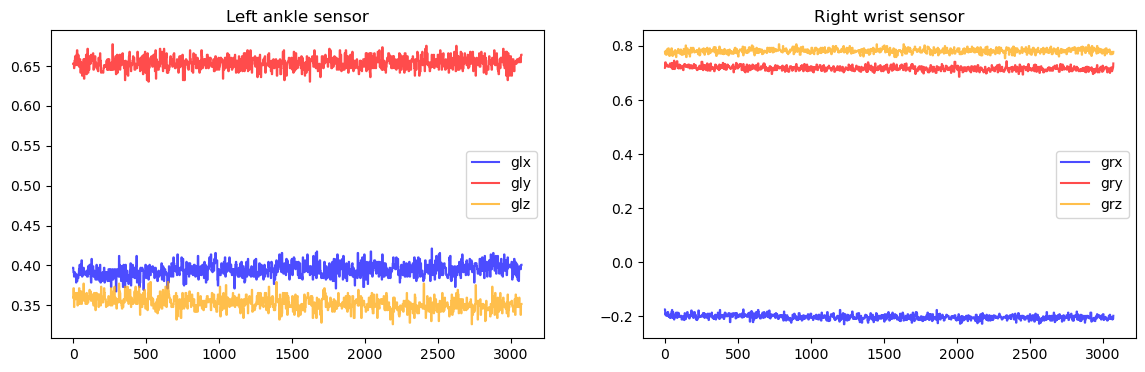

 =================Walking (1 min) - a===================


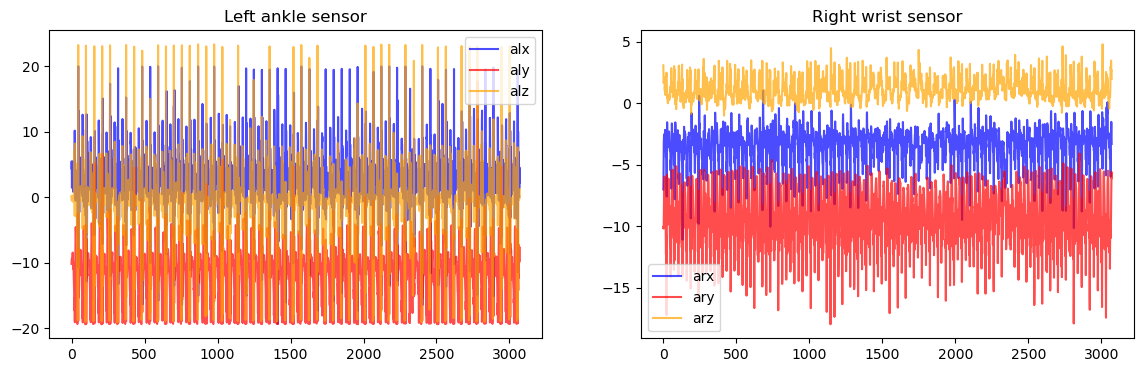

 =================Walking (1 min) - g===================


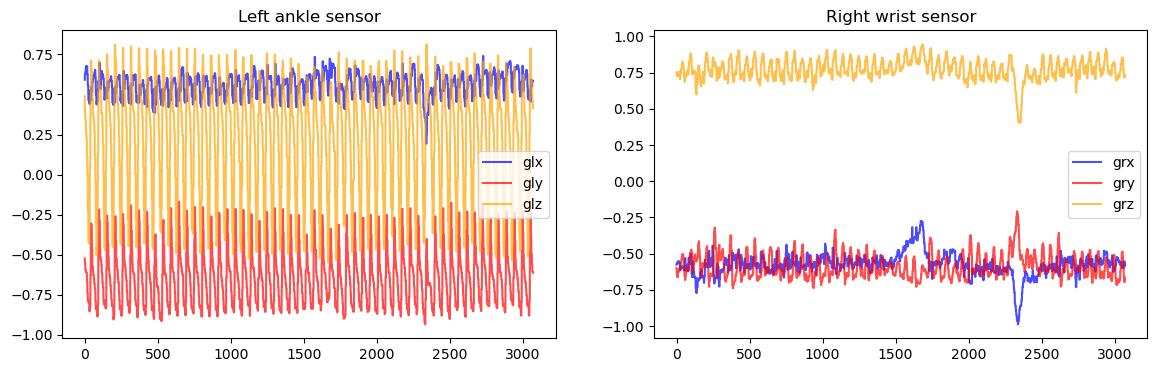

 =================Climbing stairs (1 min) - a===================


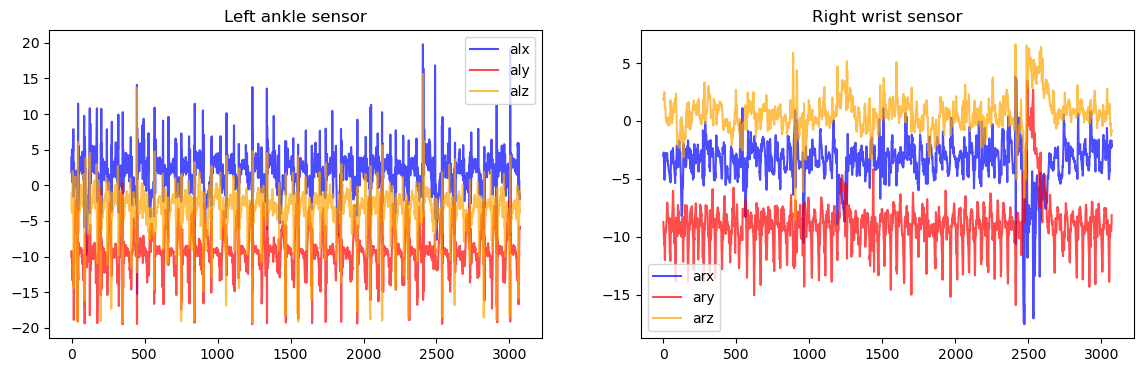

 =================Climbing stairs (1 min) - g===================


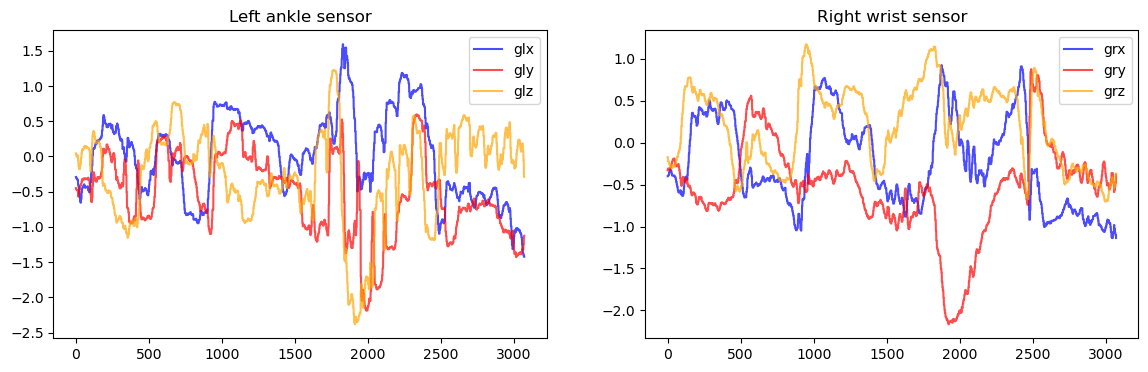

 =================Waist bends forward (20x) - a===================


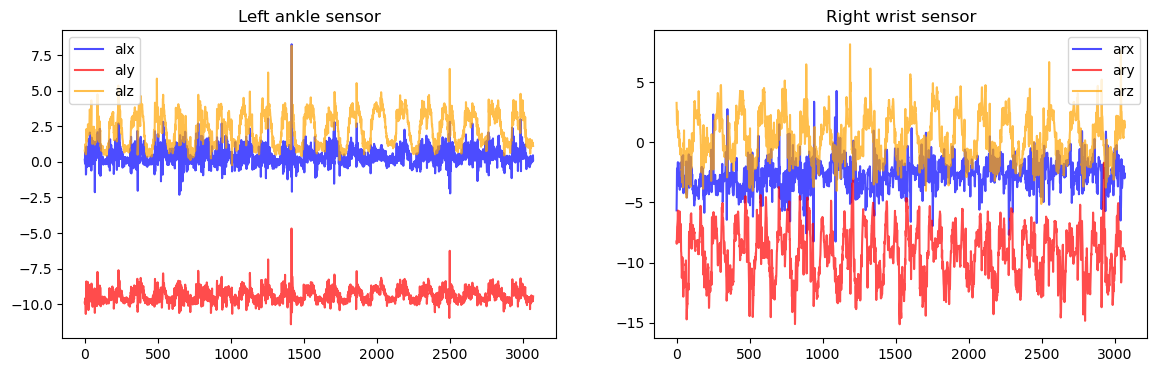

 =================Waist bends forward (20x) - g===================


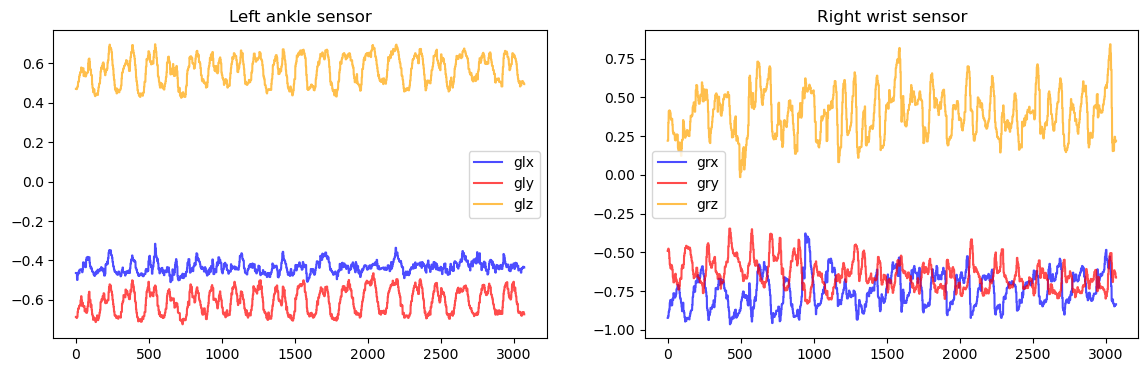

 =================Frontal elevation of arms (20x) - a===================


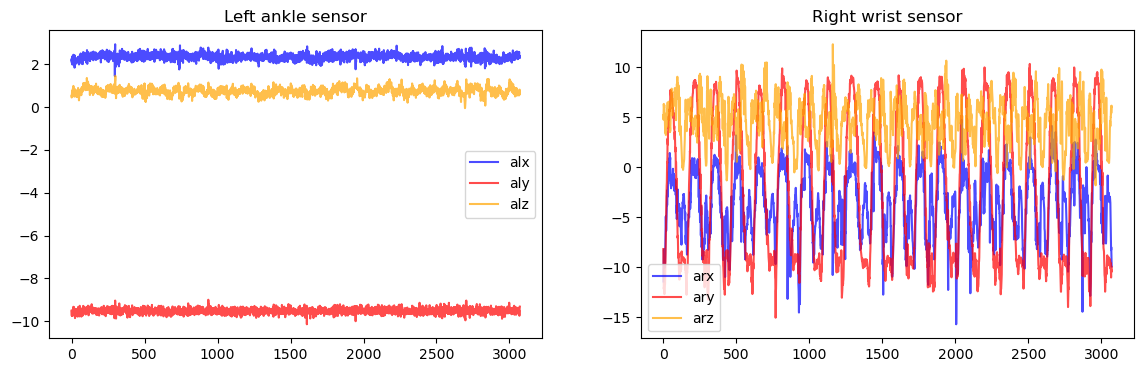

 =================Frontal elevation of arms (20x) - g===================


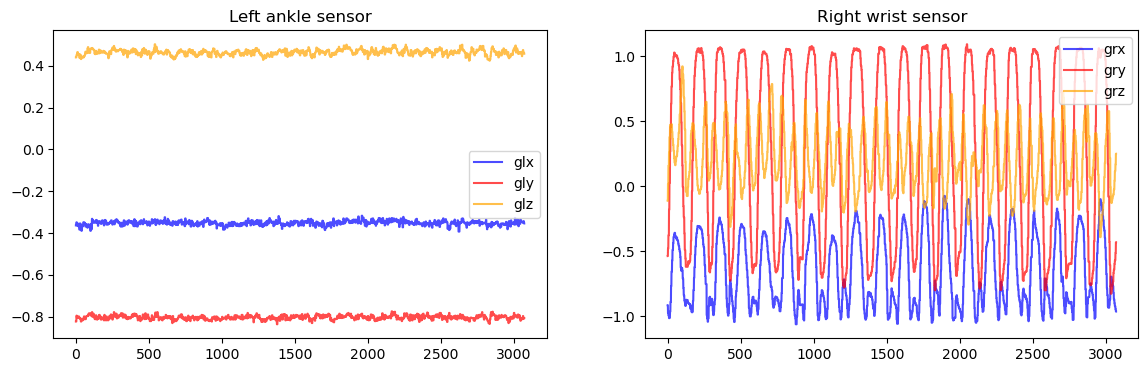

 =================Knees bending (crouching) (20x) - a===================


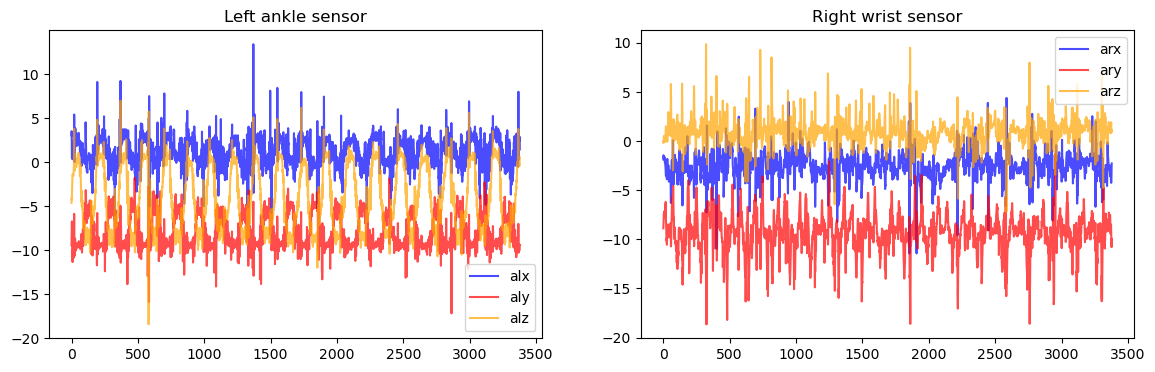

 =================Knees bending (crouching) (20x) - g===================


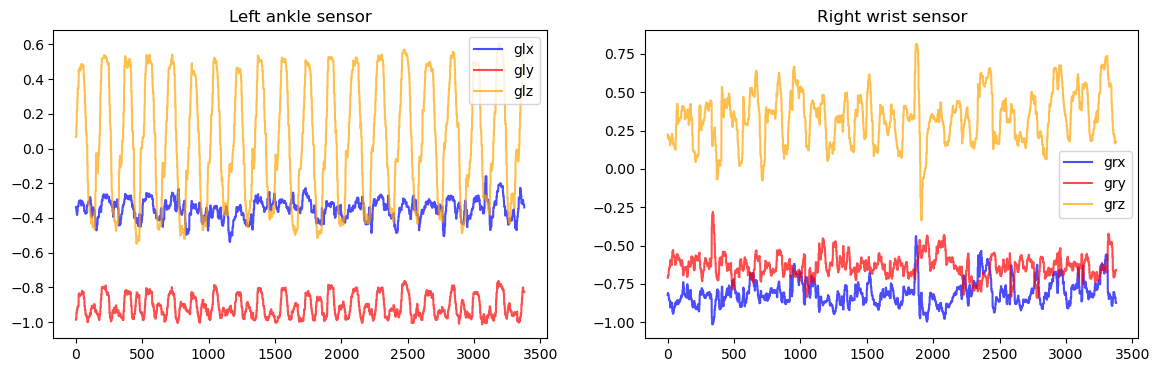

 =================Cycling (1 min) - a===================


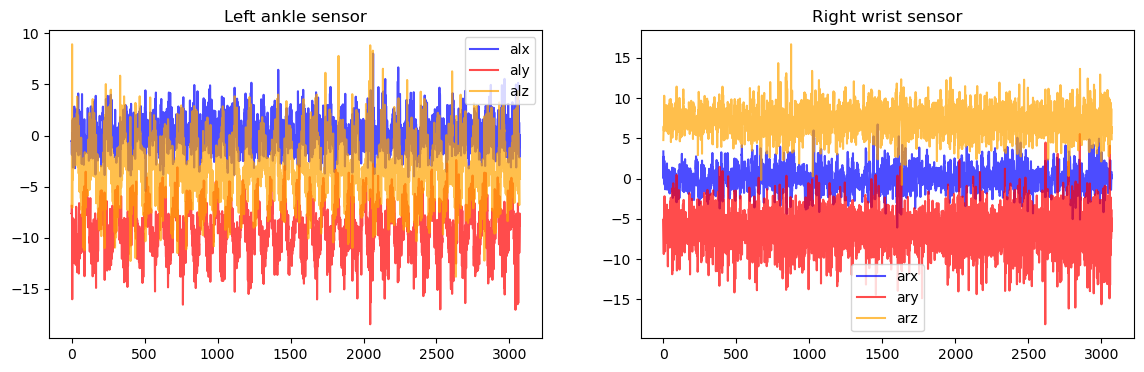

 =================Cycling (1 min) - g===================


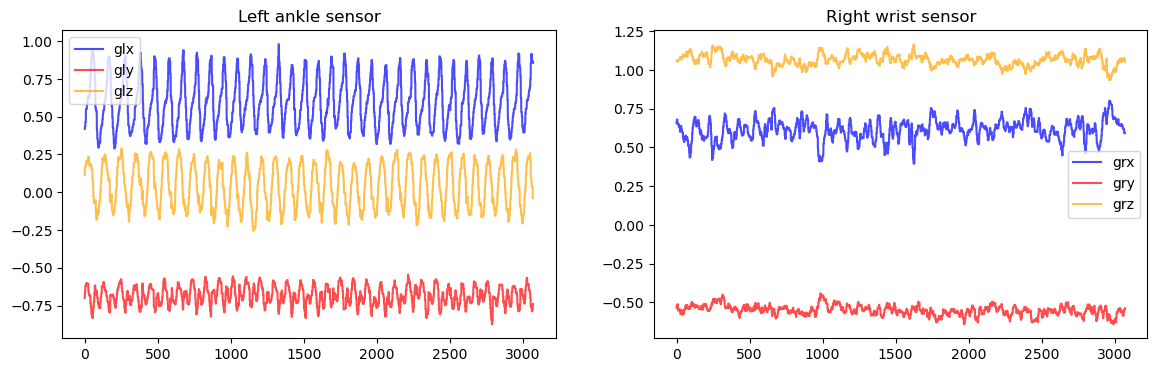

 =================Jogging (1 min) - a===================


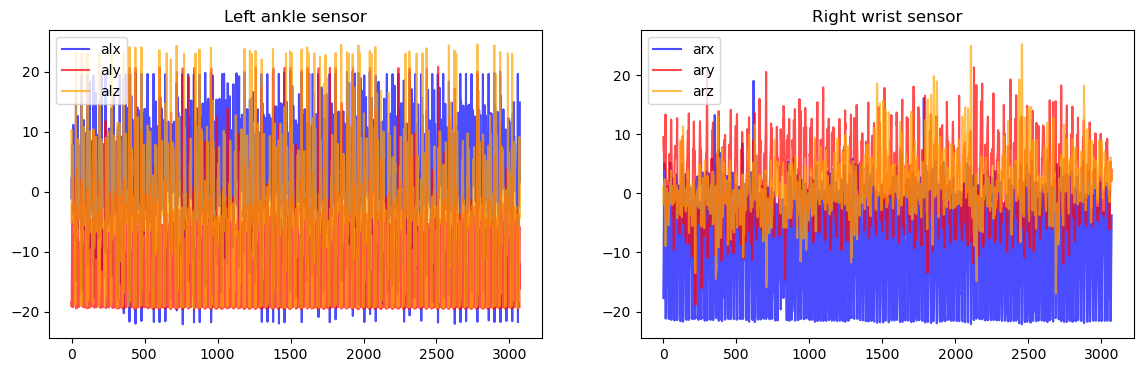

 =================Jogging (1 min) - g===================


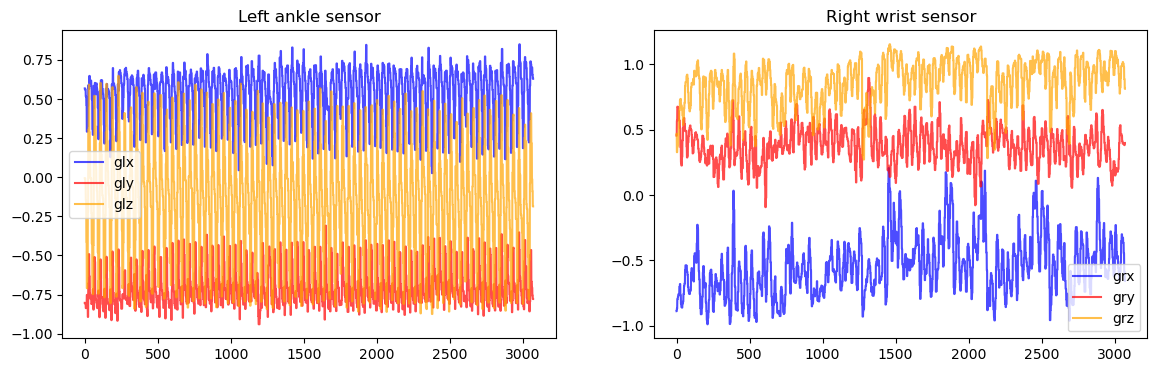

 =================Running (1 min) - a===================


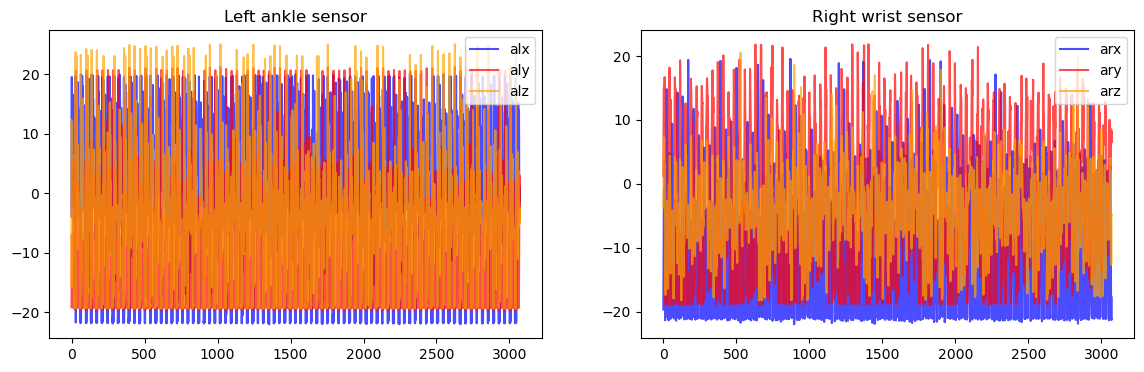

 =================Running (1 min) - g===================


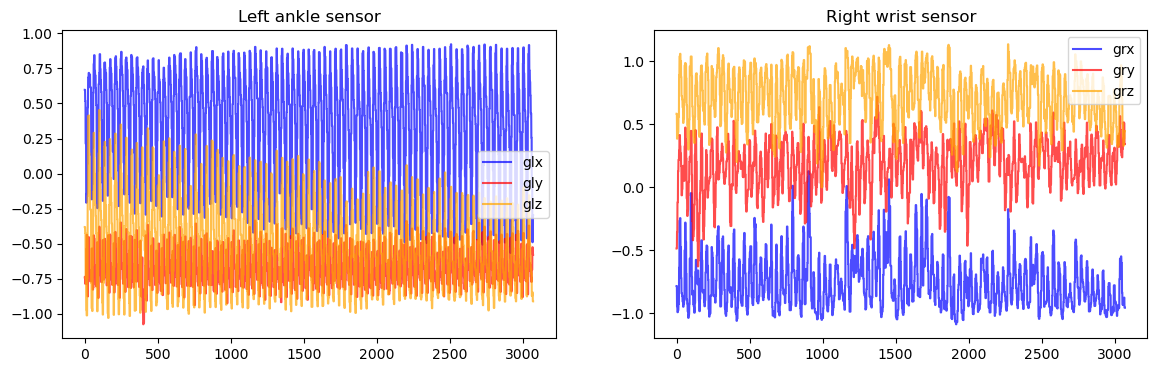

 =================Jump front & back (20x) - a===================


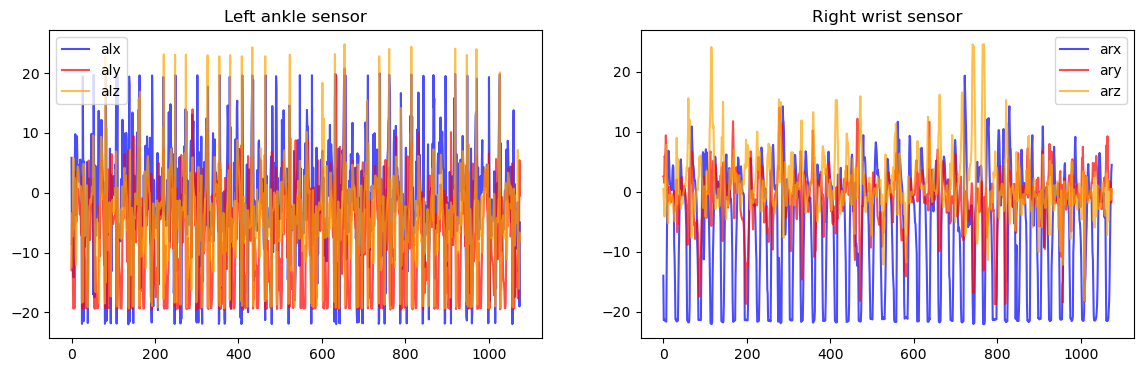

 =================Jump front & back (20x) - g===================


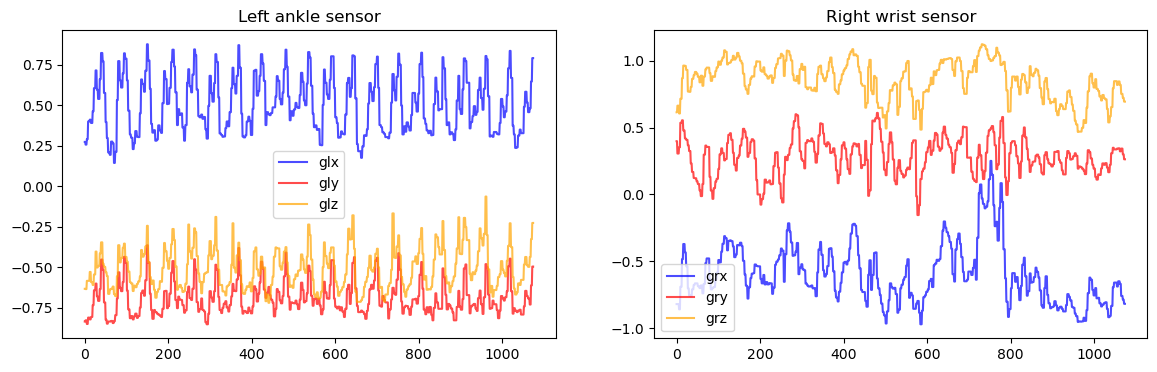

In [22]:
subject1 = df[df['subject'] == 'subject1']
readings = ['a', 'g']

for i in range(1,13):
    for r in readings:
        print(f" ================={activity_label[i]} - {r}===================")
        plt.figure(figsize=(14,4))
        plt.subplot(1,2,1)
        plt.plot(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+"lx"],
                 color = 'blue', alpha = 0.7, label = r + "lx")
        plt.plot(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+"ly"],
                 color = 'red', alpha = 0.7, label = r + "ly")
        plt.plot(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+"lz"],
                 color = 'orange', alpha = 0.7, label = r + "lz")
        plt.title("Left ankle sensor")
        plt.legend()
        plt.subplot(1,2,2)
        plt.plot(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+"rx"],
                 color = 'blue', alpha = 0.7, label = r + "rx")
        plt.plot(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+ "ry"],
                 color = 'red', alpha = 0.7, label = r + "ry")
        plt.plot(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+ "rz"],
                 color = 'orange', alpha = 0.7, label = r + "rz")
        plt.title("Right wrist sensor")
        plt.legend()
        plt.show()


 =================Standing still (1 min) - a===================


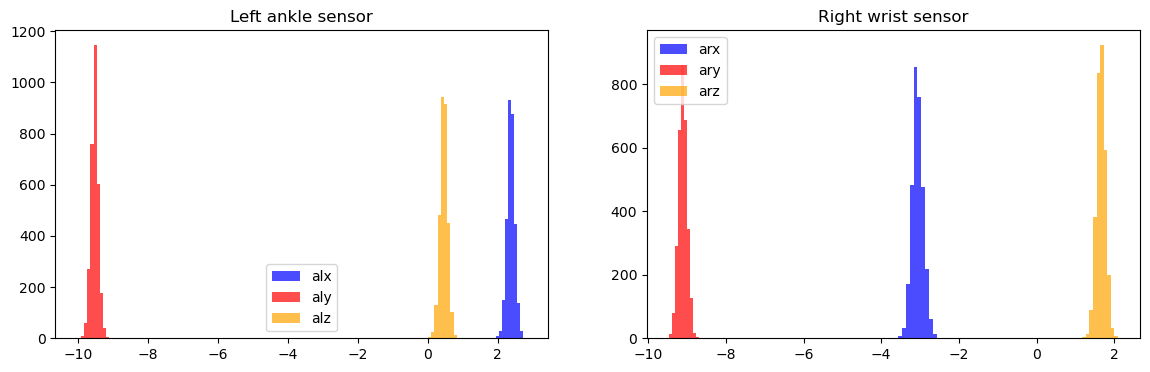

 =================Standing still (1 min) - g===================


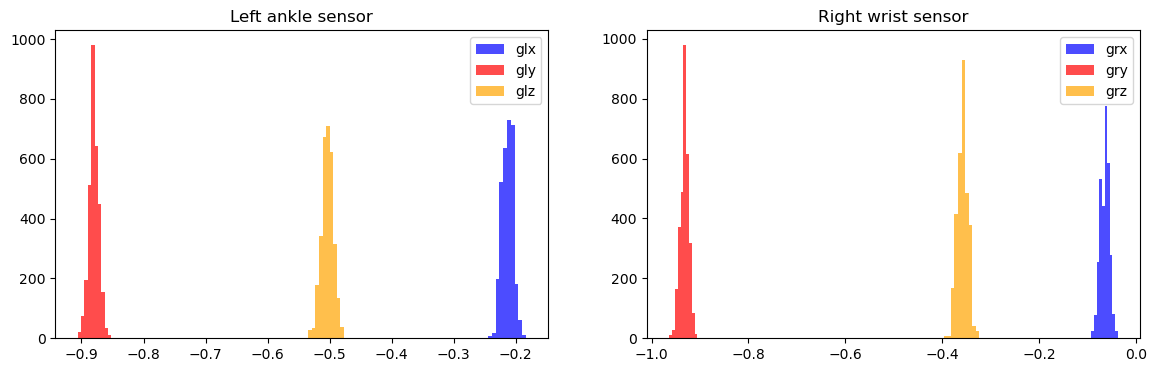

 =================Sitting and relaxing (1 min) - a===================


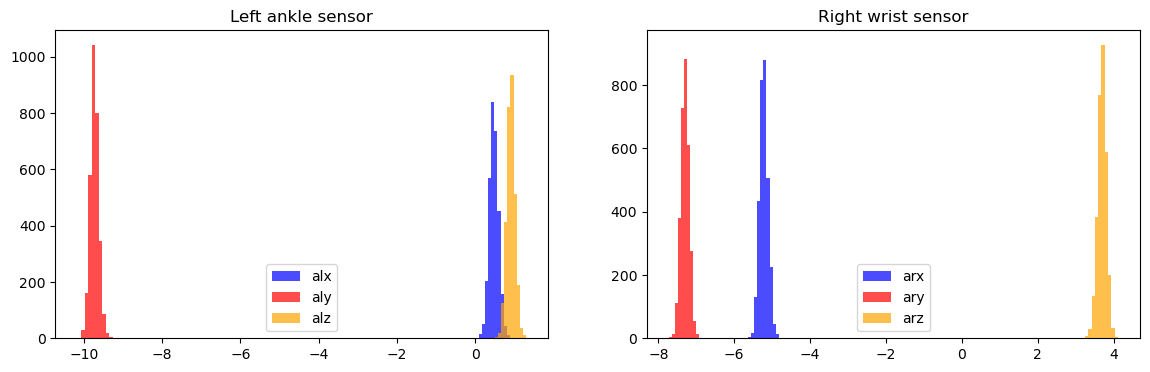

 =================Sitting and relaxing (1 min) - g===================


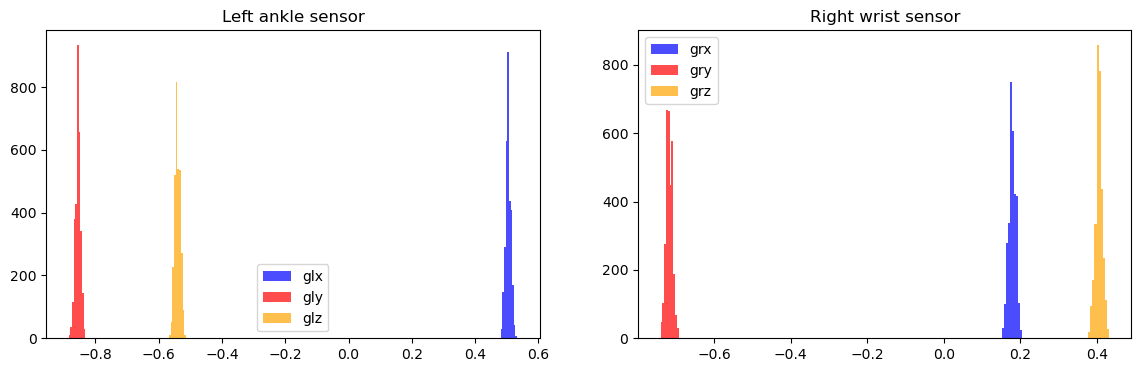

 =================Lying down (1 min) - a===================


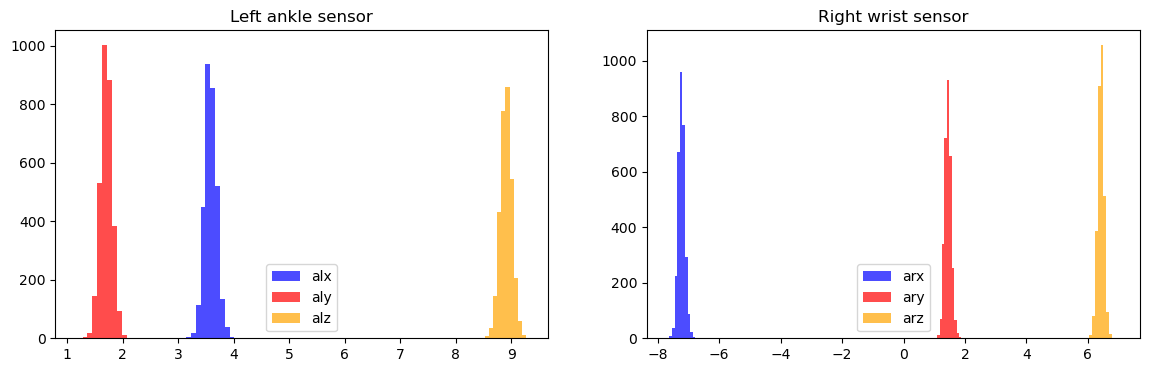

 =================Lying down (1 min) - g===================


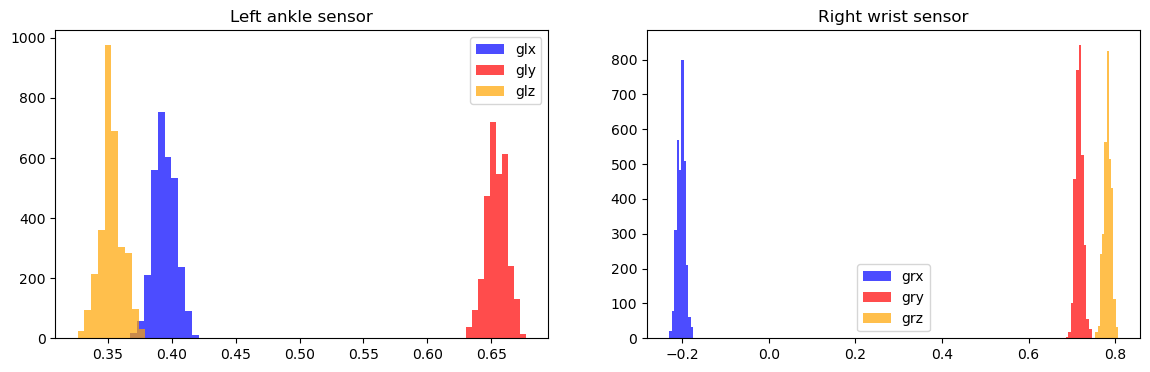

 =================Walking (1 min) - a===================


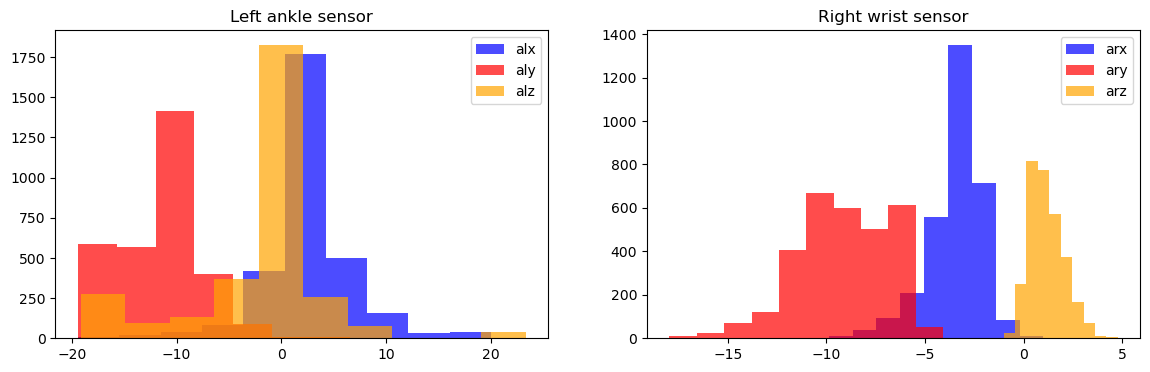

 =================Walking (1 min) - g===================


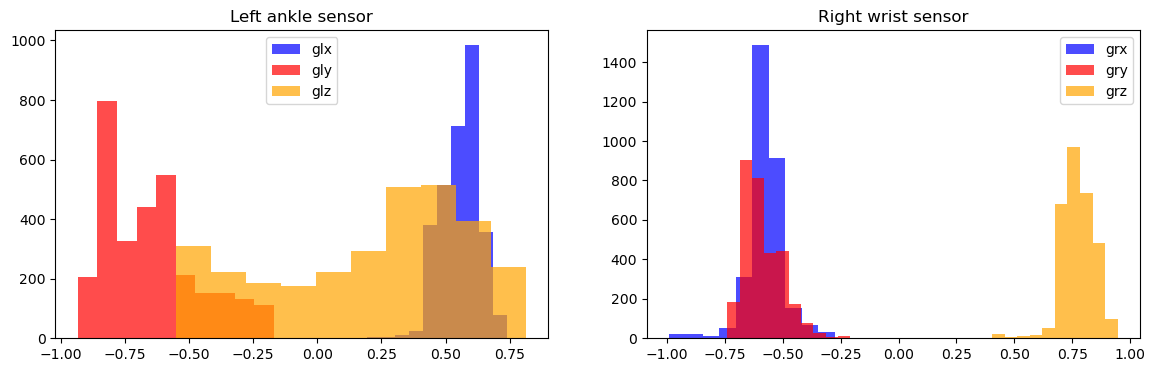

 =================Climbing stairs (1 min) - a===================


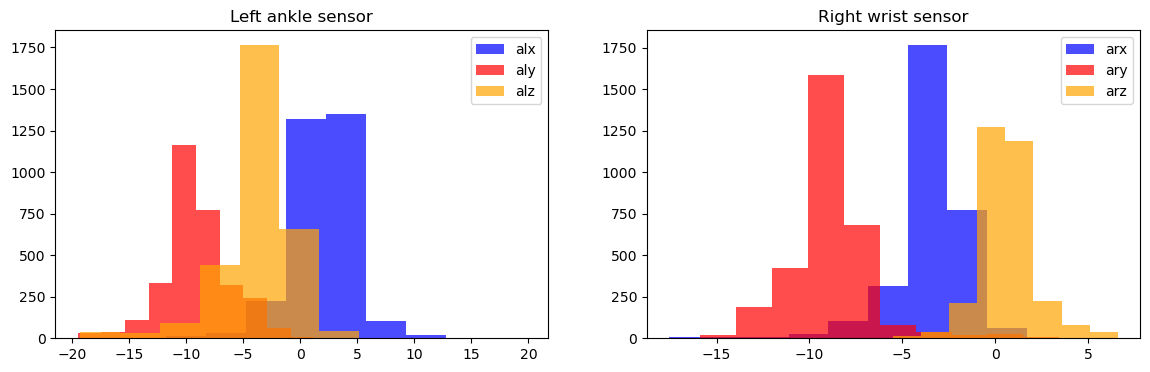

 =================Climbing stairs (1 min) - g===================


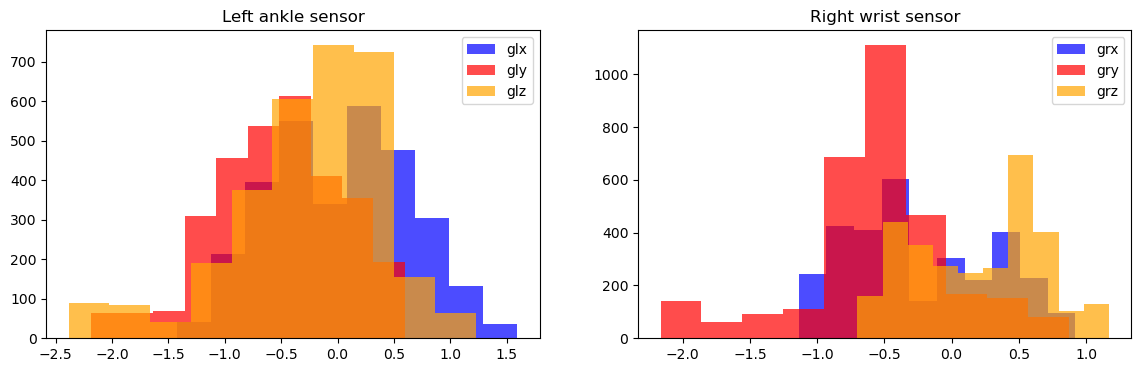

 =================Waist bends forward (20x) - a===================


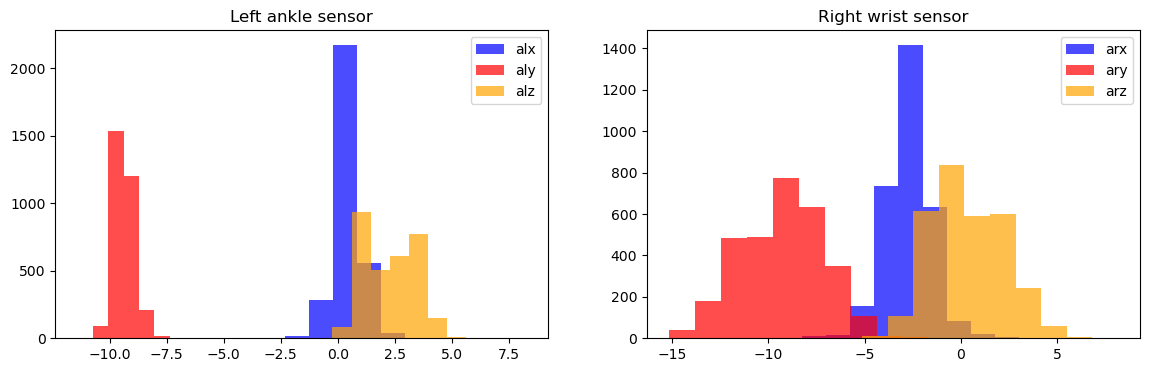

 =================Waist bends forward (20x) - g===================


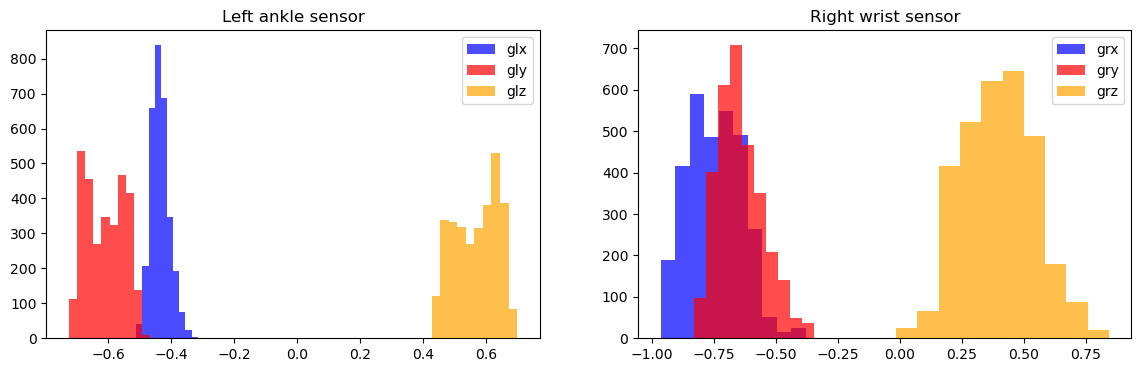

 =================Frontal elevation of arms (20x) - a===================


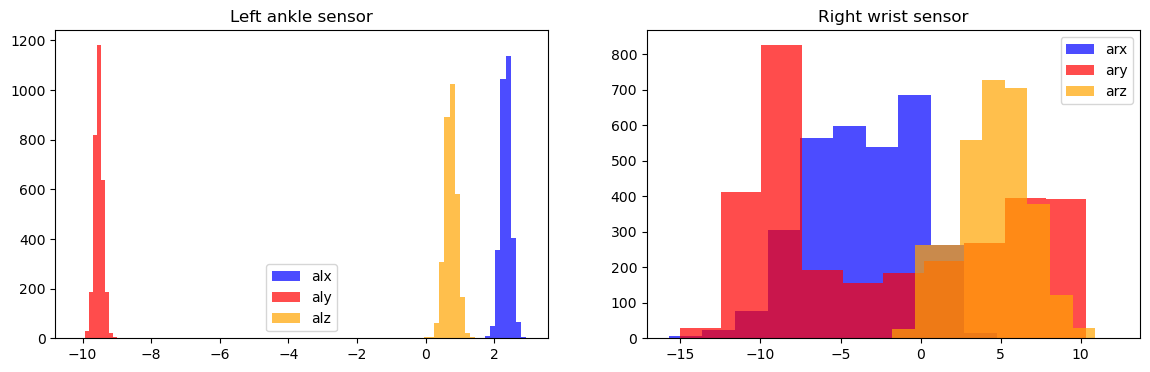

 =================Frontal elevation of arms (20x) - g===================


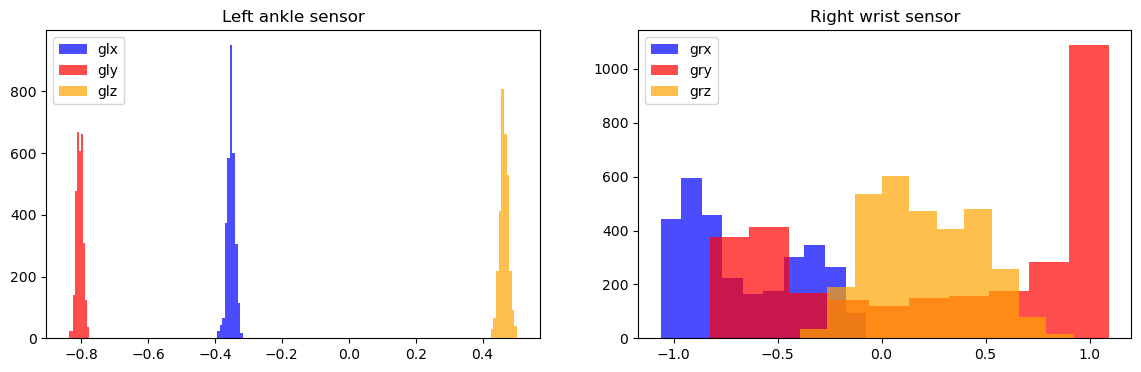

 =================Knees bending (crouching) (20x) - a===================


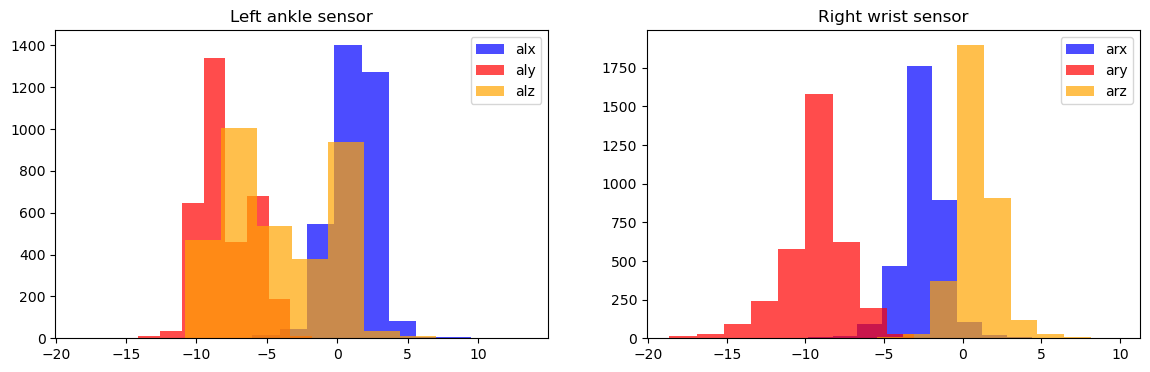

 =================Knees bending (crouching) (20x) - g===================


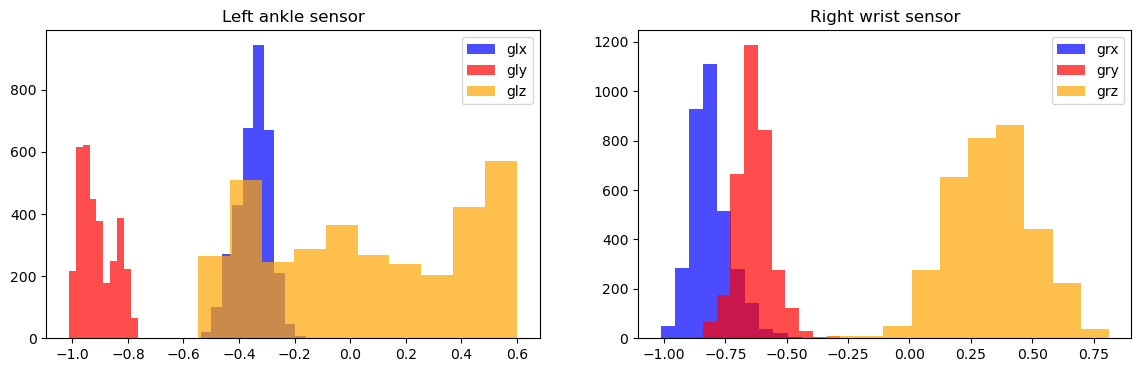

 =================Cycling (1 min) - a===================


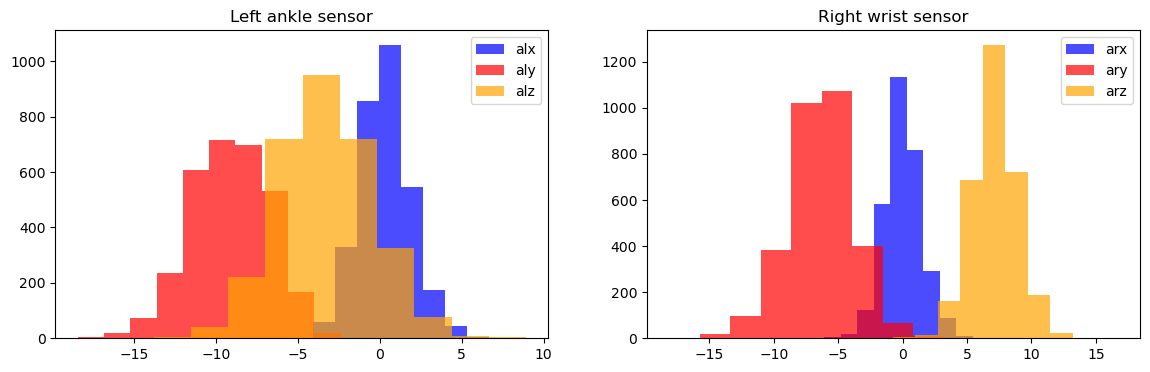

 =================Cycling (1 min) - g===================


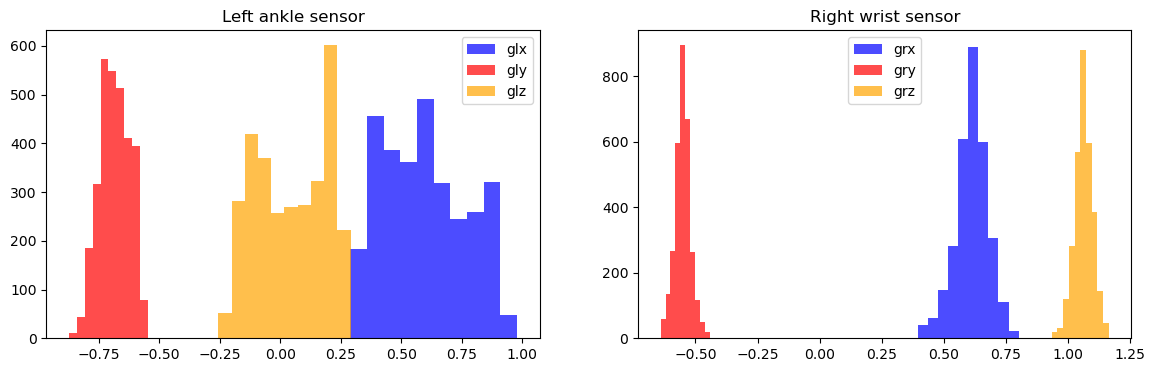

 =================Jogging (1 min) - a===================


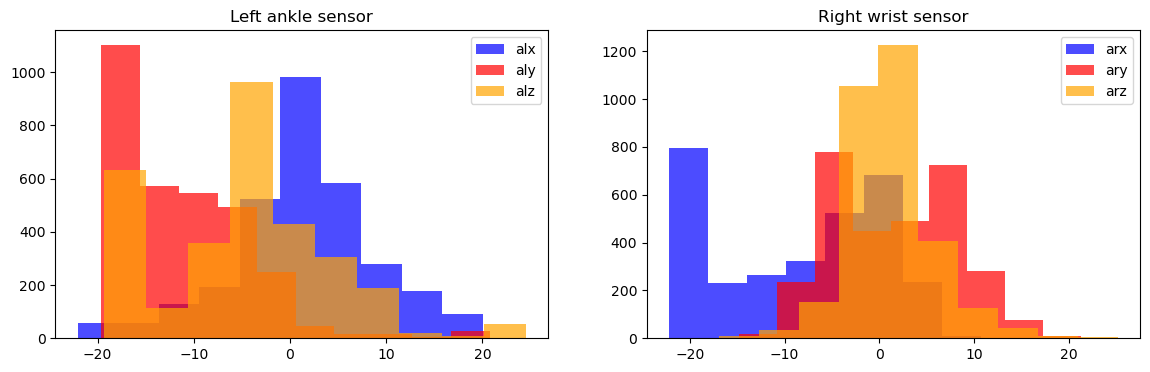

 =================Jogging (1 min) - g===================


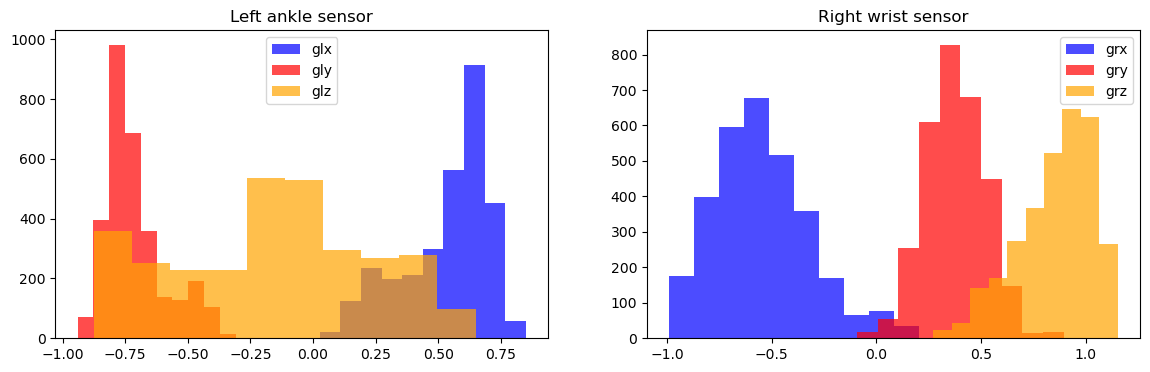

 =================Running (1 min) - a===================


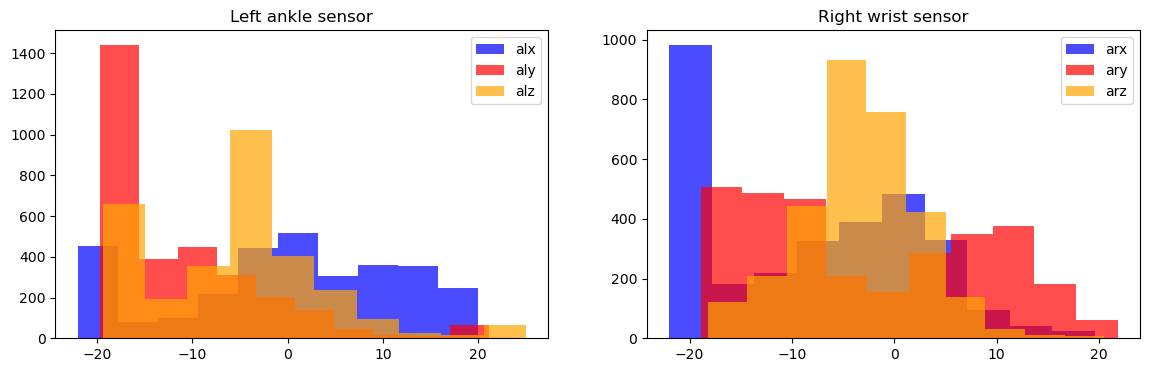

 =================Running (1 min) - g===================


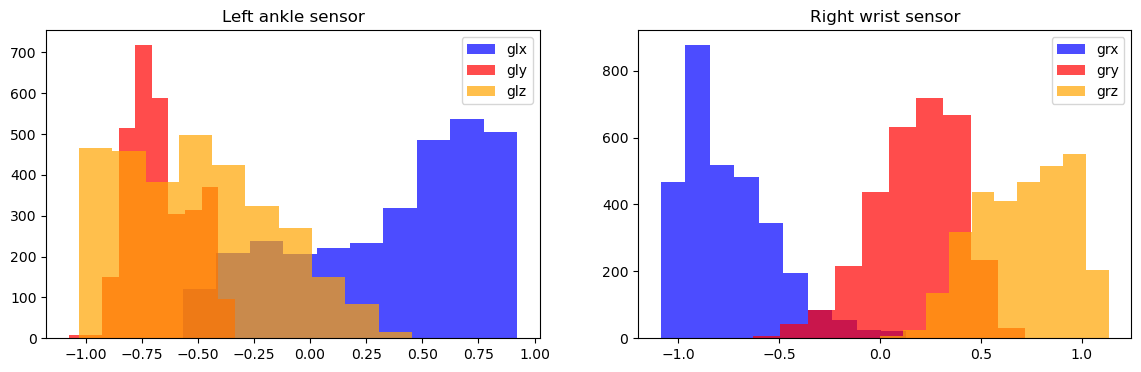

 =================Jump front & back (20x) - a===================


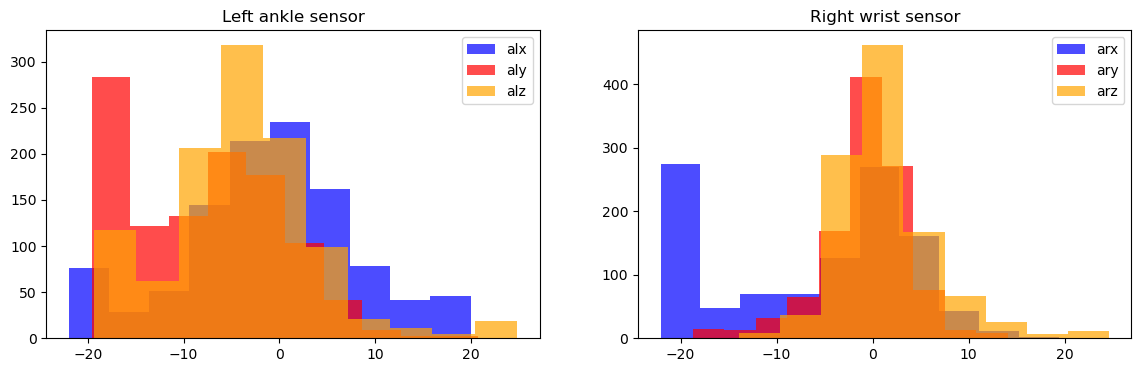

 =================Jump front & back (20x) - g===================


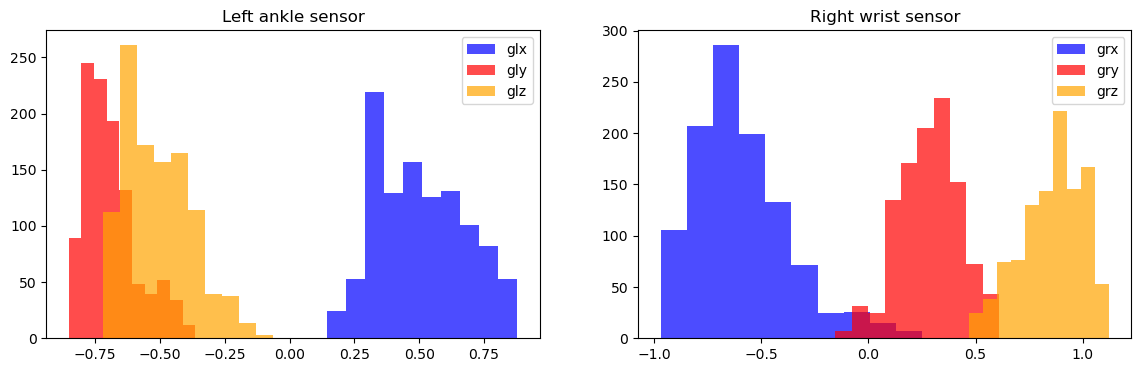

In [23]:
subject1 = df[df['subject'] == 'subject1']
readings = ['a', 'g']

for i in range(1,13):
    for r in readings:
        print(f" ================={activity_label[i]} - {r}===================")
        plt.figure(figsize=(14,4))
        plt.subplot(1,2,1)
        plt.hist(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+"lx"],
                 color = 'blue', alpha = 0.7, label = r + "lx")
        plt.hist(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+"ly"],
                 color = 'red', alpha = 0.7, label = r + "ly")
        plt.hist(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+"lz"],
                 color = 'orange', alpha = 0.7, label = r + "lz")
        plt.title("Left ankle sensor")
        plt.legend()
        plt.subplot(1,2,2)
        plt.hist(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+"rx"],
                 color = 'blue', alpha = 0.7, label = r + "rx")
        plt.hist(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+ "ry"],
                 color = 'red', alpha = 0.7, label = r + "ry")
        plt.hist(subject1[subject1['Activity'] == i].reset_index(drop=True)[r+ "rz"],
                 color = 'orange', alpha = 0.7, label = r + "rz")
        plt.title("Right wrist sensor")
        plt.legend()
        plt.show()

In [24]:
df['Activity']=df['Activity'].replace([0,1,2,3,4,5,6,7,8,9,10,11,12],['None',
                                                                    'Standing still (1 min)',
                                                                    'Sitting and relaxing (1 min)',
                                                                    'Lying down (1 min)',
                                                                    'Walking (1 min)',
                                                                    'Climbing stairs (1 min)',
                                                                    'Waist bends forward (20x)',
                                                                    'Frontal elevation of arms (20x)',
                                                                    'Knees bending (crouching) (20x)',
                                                                    'Cycling (1 min)','Jogging (1 min)',
                                                                    'Running (1 min)','Jump front & back (20x)'])

In [25]:
df["Activity"]

941653                        None
420654                        None
183725                        None
558607                        None
946012                        None
                    ...           
1213641    Jump front & back (20x)
1213642    Jump front & back (20x)
1213643    Jump front & back (20x)
1213644    Jump front & back (20x)
1213645    Jump front & back (20x)
Name: Activity, Length: 383195, dtype: object

In [26]:
df.Activity.value_counts()

Activity
None                               40000
Standing still (1 min)             30720
Sitting and relaxing (1 min)       30720
Lying down (1 min)                 30720
Walking (1 min)                    30720
Cycling (1 min)                    30720
Climbing stairs (1 min)            30720
Running (1 min)                    30720
Jogging (1 min)                    30720
Frontal elevation of arms (20x)    29441
Knees bending (crouching) (20x)    29337
Waist bends forward (20x)          28315
Jump front & back (20x)            10342
Name: count, dtype: int64

<Axes: ylabel='count'>

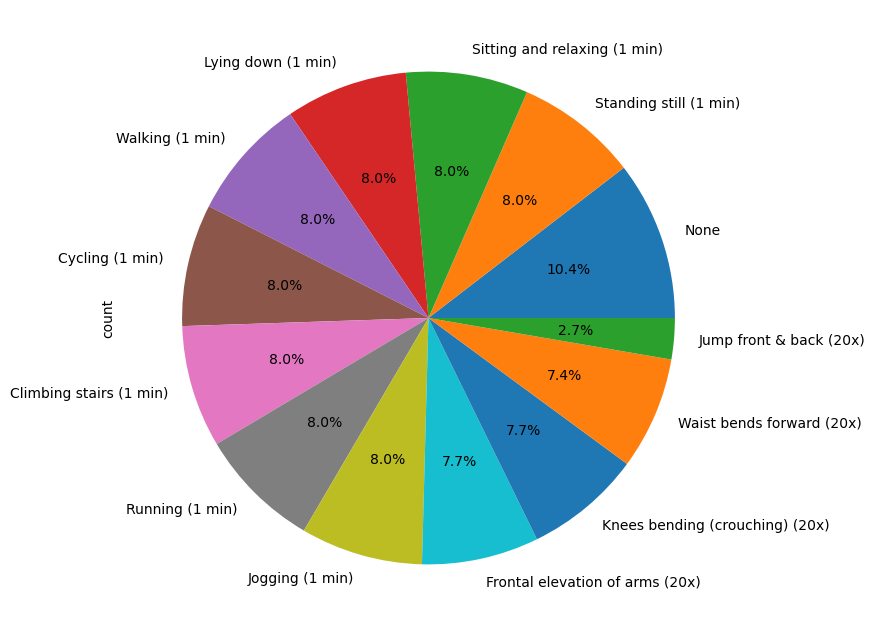

In [27]:
plt.figure(figsize=(12,8))
round(df["Activity"].value_counts()/df.shape[0]*100,2).plot.pie(autopct='%2.1f%%')

In [28]:
df1 = df.copy()

for feature in df1.columns[ :- 2]:
    lower_range = np.quantile(df[feature], 0.01)
    upper_range = np.quantile(df[feature], 0.99)
    print(feature, "range:", lower_range, 'to', upper_range)
    df1 = df1.drop(df1[(df1[feature] >upper_range) | (df1[feature] < lower_range)].index, axis = 0)
    print('shape', df1.shape)

alx range: -11.52612 to 19.223
shape (375532, 14)
aly range: -19.378 to 2.3864839999999967
shape (369620, 14)
alz range: -18.949 to 14.138059999999998
shape (365810, 14)
glx range: -0.75139 to 0.80891
shape (358785, 14)
gly range: -1.0694 to 0.96435
shape (352007, 14)
glz range: -1.1061 to 0.8290799999999999
shape (346364, 14)
arx range: -21.486 to 9.015735999999999
shape (341145, 14)
ary range: -18.691 to 11.827
shape (334934, 14)
arz range: -10.26506 to 11.783059999999997
shape (332266, 14)
grx range: -1.0216 to 0.95294
shape (328582, 14)
gry range: -1.1437 to 0.9117
shape (323546, 14)
grz range: -0.7069 to 1.125
shape (318831, 14)


In [29]:
df1

,alx,aly,alz,glx,gly,glz,arx,ary,arz,grx,gry,grz,Activity,subject
941653,1.70090,-9.59080,1.31870,-0.077922,-0.68293,0.63065,-3.6217,-6.507700,6.22670,-0.77647,-0.17248,0.803880,None,subject8
183725,1.03940,-9.10900,1.97160,-0.538030,-0.32833,0.66405,-3.7056,-6.609500,6.05490,-0.99804,-0.70226,0.355600,None,subject2
558607,1.54980,-9.79910,0.28596,-0.641930,-0.77674,0.16110,-2.0357,-9.562900,0.70935,-0.86471,-0.60370,0.137930,None,subject5
946012,3.12240,-9.49820,-0.31869,0.710580,-0.43902,-0.84676,-1.8502,-6.179300,7.06600,0.34706,-1.13760,0.314660,None,subject8
250316,0.91097,-9.64510,0.83936,-0.562150,-0.74109,0.33399,-5.6077,-3.894400,5.55530,-0.98431,-0.26283,0.439660,None,subject2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1213636,-0.19979,-0.93484,2.55540,0.630800,-0.52533,-0.67976,-4.0212,-0.082645,0.73545,-0.45882,-1.00000,0.122840,Jump front & back (20x),subject10
1213637,-0.33315,-1.23710,-2.91940,0.638220,-0.42777,-0.74853,-2.2515,-0.414790,0.52093,-0.41765,-1.03700,0.088362,Jump front & back (20x),subject10
1213640,6.77570,-15.07500,7.39740,0.619670,-0.33771,-0.82711,-2.2797,-2.358900,2.11120,-0.41765,-1.03700,0.088362,Jump front & back (20x),subject10
1213641,-2.48730,-19.23300,3.46140,0.619670,-0.33771,-0.82711,-8.2348,-4.965200,2.48090,-0.43725,-1.01850,0.079741,Jump front & back (20x),subject10


## Step 4: Data Processing

In [30]:
le = LabelEncoder()
df['subject'] = le.fit_transform(df['subject'])

In [31]:
df['Activity'] = le.fit_transform(df['Activity'])

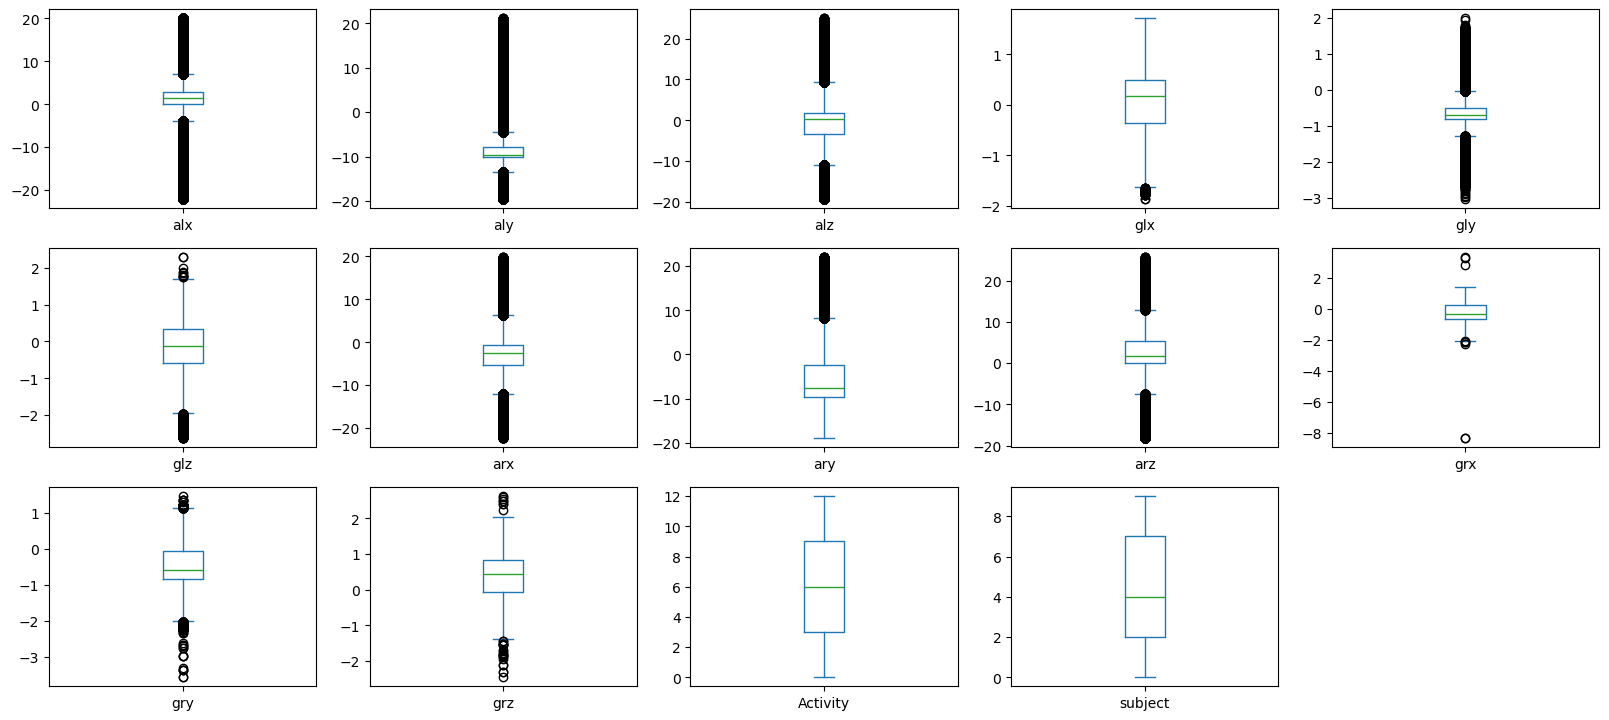

In [32]:
df.plot(kind='box', subplots=True, layout = (5,5), figsize=(20,15))
plt.show()

In [33]:
X = df.drop(["Activity", "subject"], axis = 1) . values
y = df['Activity' ].values

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)

In [35]:
ro_scaler = RobustScaler().fit(X_train)
X_train_scaled = ro_scaler.transform(X_train)
X_test_scaled = ro_scaler.transform(X_test)

## Step 5:Building Models 

In [50]:
def resultsSummarizer(y_true, y_pred, cm_en = True):
    cm = confusion_matrix(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro')
    rec = sensitivity = recall_score(y_true, y_pred, average='macro' )
    f1= f1_score(y_true, y_pred, average='macro')
    if cm_en:
        plt.figure(figsize=(15,15))
    
    
        sns.heatmap(cm, annot = True, cmap = "Blues", xticklabels=activity_label.values(),
                yticklabels=activity_label.values())
    
        plt.title('Confusion Matrix')
        plt.show()
    
    print(f'Accuracy Score: '+'{: .4%}' . format (acc))
    print(f'Precision Score: '+'{: .4%}'. format(prec))
    print(f'Recall Score: ' + '{: .4%}'.format(rec))
    print(f'F1 Score: ' + '{: .4%}'.format(f1))



### 1.LogisticRegration()

In [37]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [38]:

lr.score(X_train, y_train)

0.5483827193141171

In [39]:
lr.score(X_test, y_test)

0.5473334794726459

In [40]:
lr2 = LogisticRegression()
lr2.fit(X_train_scaled, y_train)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [41]:
lr2.score(X_train_scaled, y_train)

0.5524676752633997

In [42]:
lr2.score(X_test_scaled, y_test)

0.5498074092631448

In [43]:
y_pred_lr = lr2.predict(X_test_scaled)

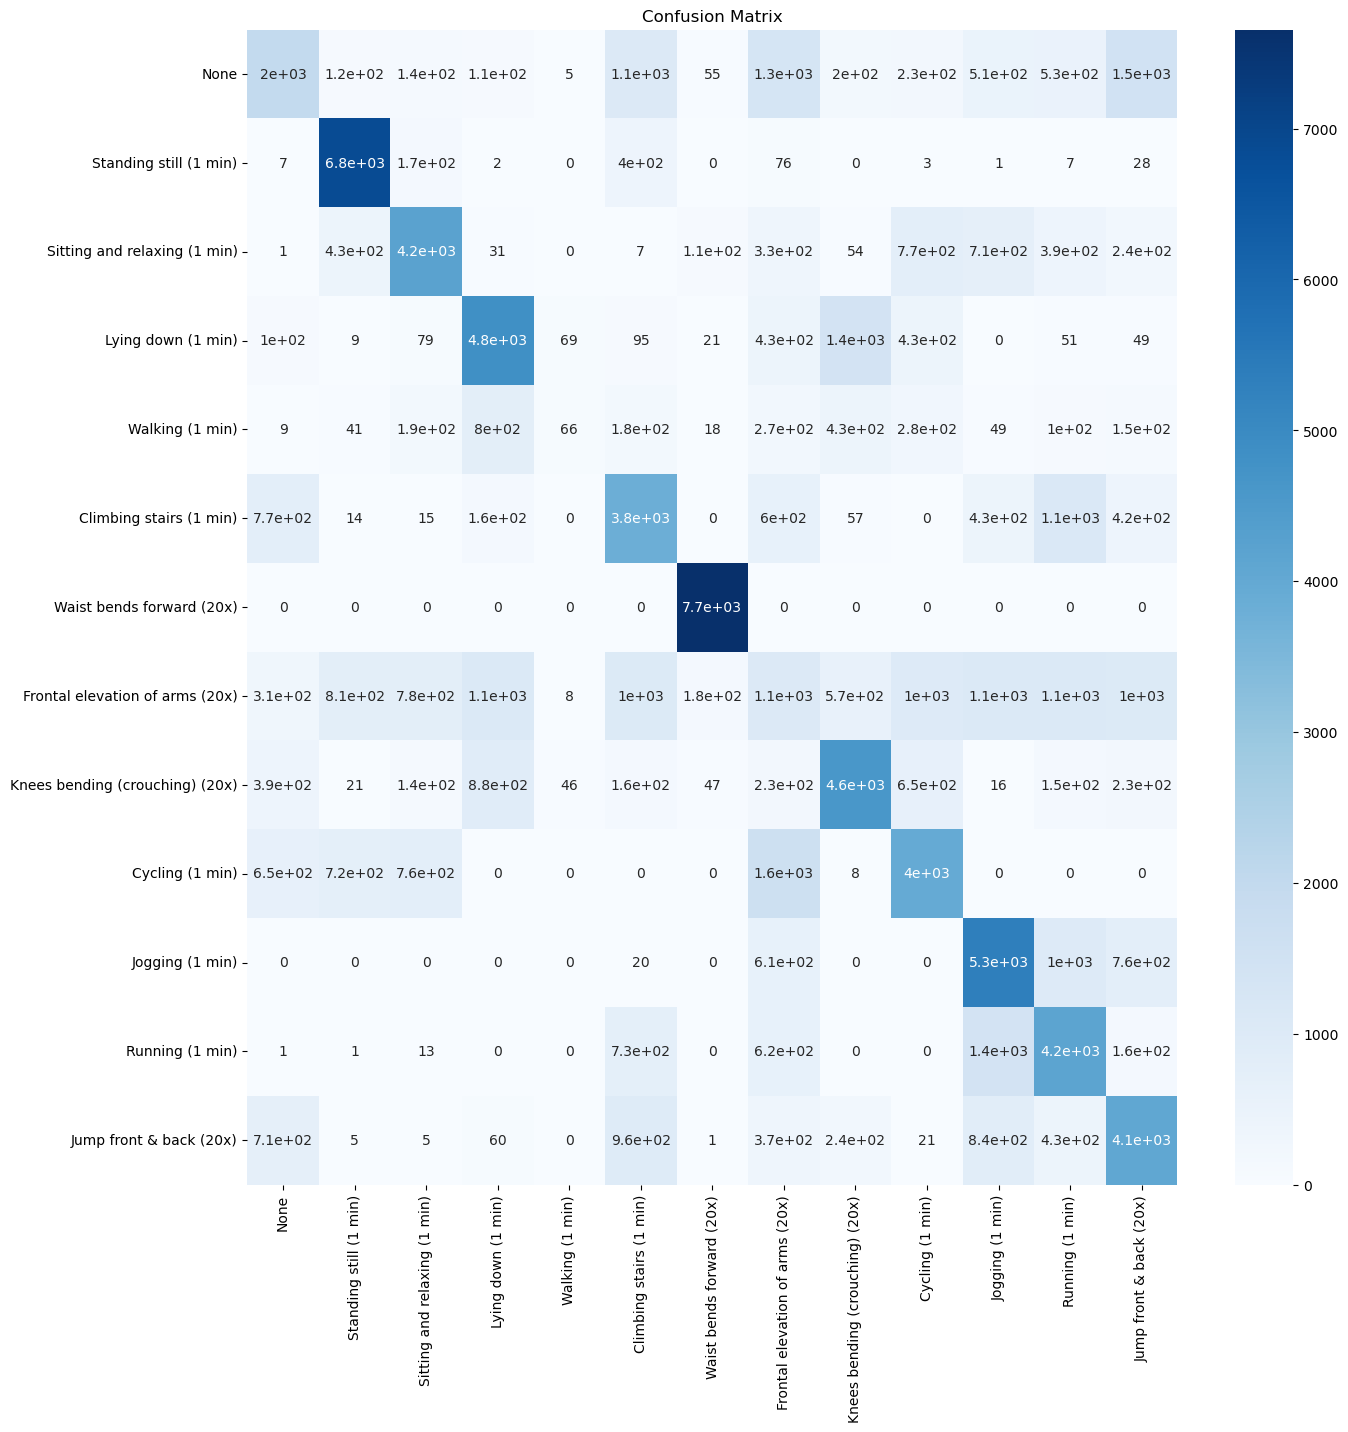

Accuracy Score:  54.9807%
Precision Score:  52.9966%
Recall Score:  53.4744%
F1 Score:  51.7877%


In [44]:
resultsSummarizer(y_test, y_pred_lr)

## 2.KNN

In [45]:
knn1 = KNeighborsClassifier(n_neighbors=5)
knn1.fit(X_train, y_train)

KNeighborsClassifier()

In [46]:
y_pred_knn = knn1.predict(X_test)

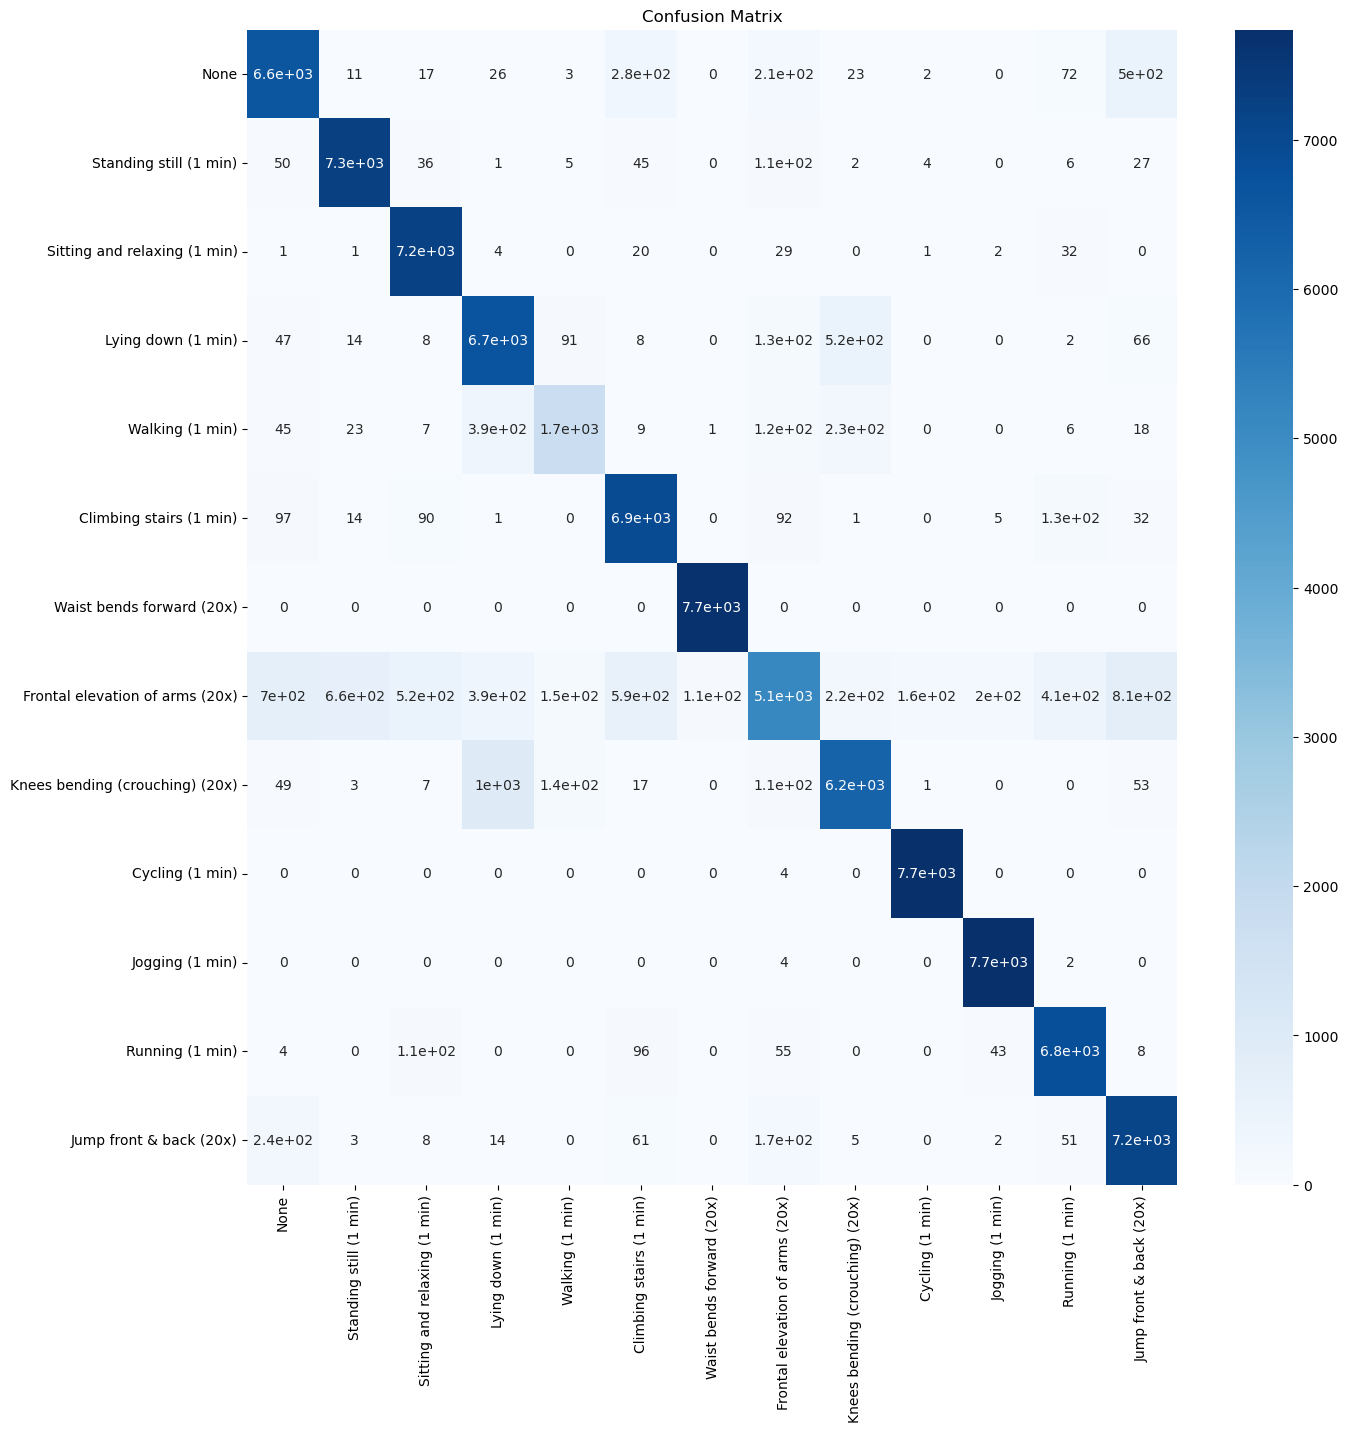

Accuracy Score:  88.6084%
Precision Score:  88.2273%
Recall Score:  88.4950%
F1 Score:  87.9214%


In [47]:
resultsSummarizer(y_test, y_pred_knn)

In [51]:
knn2 = KNeighborsClassifier(n_neighbors=5)
knn2.fit(X_train_scaled, y_train)
y_pred_knn2=knn2.predict(X_test_scaled)

In [52]:
resultsSummarizer(y_test, y_pred_knn2, cm_en=False)

Accuracy Score:  93.7828%
Precision Score:  93.6898%
Recall Score:  93.6127%
F1 Score:  93.3125%


In [53]:
for n in range(1,11):
    knn = KNeighborsClassifier(n_neighbors=n)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    print(f"\n ============ No of Neighbors: {n}========== \n")
    resultsSummarizer(y_test, y_pred, cm_en=False)



 ============ No of Neighbors: 1========== 

Accuracy Score:  93.9509%
Precision Score:  93.7228%
Recall Score:  93.7969%
F1 Score:  93.6643%

 ============ No of Neighbors: 2========== 

Accuracy Score:  93.1878%
Precision Score:  92.9340%
Recall Score:  93.0765%
F1 Score:  92.8154%

 ============ No of Neighbors: 3========== 

Accuracy Score:  94.0772%
Precision Score:  93.9519%
Recall Score:  93.8988%
F1 Score:  93.6336%

 ============ No of Neighbors: 4========== 

Accuracy Score:  93.8037%
Precision Score:  93.6654%
Recall Score:  93.6047%
F1 Score:  93.3161%

 ============ No of Neighbors: 5========== 

Accuracy Score:  93.7828%
Precision Score:  93.6898%
Recall Score:  93.6127%
F1 Score:  93.3125%

 ============ No of Neighbors: 6========== 

Accuracy Score:  93.5720%
Precision Score:  93.4854%
Recall Score:  93.3641%
F1 Score:  93.0438%

 ============ No of Neighbors: 7========== 

Accuracy Score:  93.5135%
Precision Score:  93.4728%
Recall Score:  93.3119%
F1 Score:  92.9948%

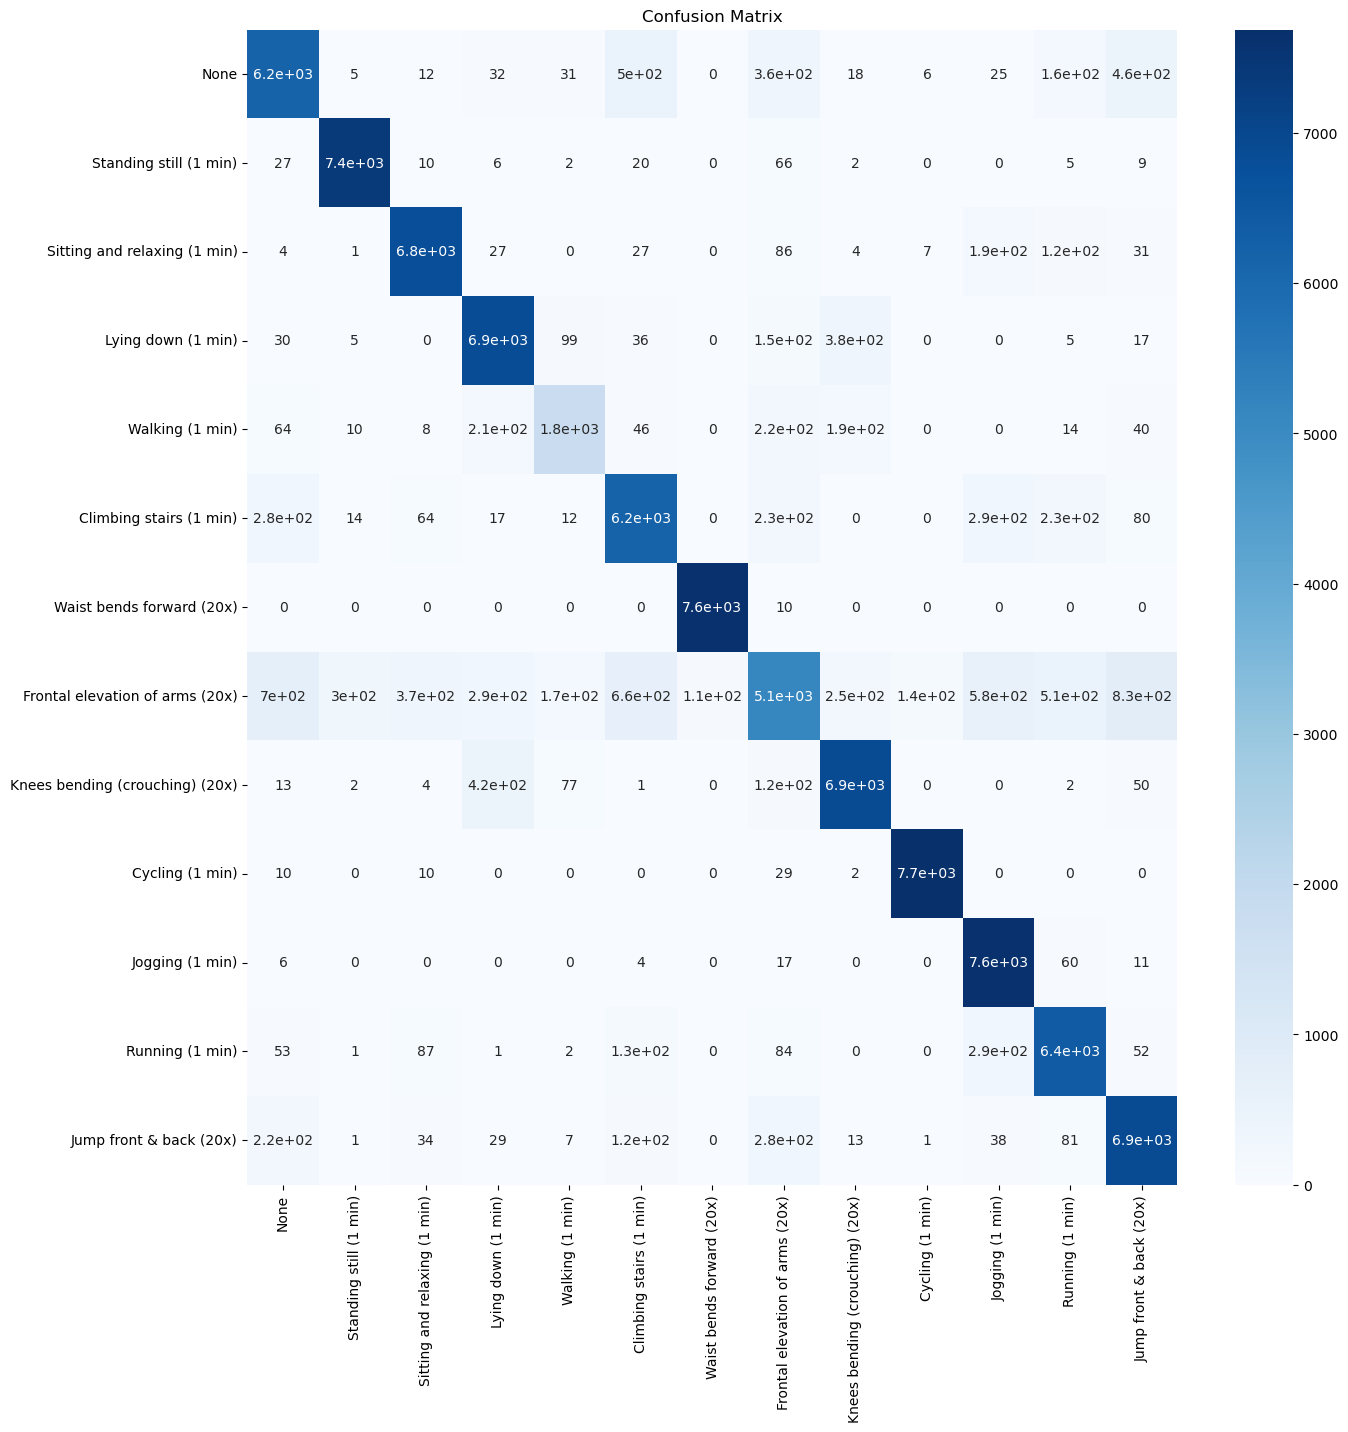

Accuracy Score:  87.2024%
Precision Score:  86.8569%
Recall Score:  87.1723%
F1 Score:  86.7146%


In [57]:
dt = DecisionTreeClassifier(max_depth=14)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
resultsSummarizer(y_test, y_pred_dt)